# SentinelX AI — Analyse exploratoire du dataset NASA C-MAPSS FD001

**Maintenance prédictive · Estimation du Remaining Useful Life (RUL)**

| Élément | Valeur |
|---|---|
| Projet | SentinelX AI — plateforme de maintenance prédictive & Maintenance Copilot RAG |
| Notebook | `01_eda_fd001_final_fusion.ipynb` |
| Dataset | NASA C-MAPSS, sous-ensemble FD001 (1 condition opérationnelle, 1 mode de panne) |
| Exigences couvertes | F-02 (EDA) · préparation de F-03 (feature pipeline) · backlog B03, B04, B05 |
| Étape suivante | `02_baseline.ipynb` — preprocessing et baseline RUL |

### Objectif

Comprendre la structure, la qualité et le comportement des données **avant** tout preprocessing ou modélisation, puis transmettre à la suite du pipeline des **décisions documentées, vérifiées et réutilisables**.

### Questions auxquelles ce notebook répond

| # | Question | Sections |
|---|---|---|
| Q1 | Les données sont-elles structurellement saines (types, manquants, doublons, continuité) ? | 3 |
| Q2 | Comment les trajectoires des moteurs sont-elles organisées et à quel point sont-elles hétérogènes ? | 4, 7 |
| Q3 | Comment séparer entraînement et validation sans fuite d'information ? | 5 |
| Q4 | Quelles variables sont constantes, quasi constantes ou réellement dynamiques ? | 6 |
| Q5 | Comment construire et valider la cible RUL, et à quoi ressemble sa distribution ? | 8, 9 |
| Q6 | Quelles variables évoluent avec le RUL, et de manière stable d'un moteur à l'autre ? | 10, 11 |
| Q7 | Quelles variables portent une information redondante ? | 12 |
| Q8 | Quels risques de data leakage faut-il verrouiller avant la modélisation ? | 13 |
| Q9 | Le jeu de test est-il cohérent avec le train, et quelles contraintes impose-t-il ? | 14 |

### Principes méthodologiques

1. **Pas de fuite d'information** — split par moteur avant toute analyse orientée cible ; `RUL_FD001.txt` n'est jamais lu.
2. **Observation ≠ preuve** — une corrélation ou un graphique formule une hypothèse ; seule la validation des modèles la confirme.
3. **Aucune sélection définitive de features** — l'EDA signale des candidats ; la décision revient aux expériences de modélisation.
4. **Reproductibilité** — graine fixe, versions et empreintes des données tracées, artefacts exportés, contrôles automatiques (`assert`).

### Sommaire

1. Configuration et reproductibilité
2. Schéma du dataset et chargement
3. Contrôles de qualité et d'intégrité
4. Structure des trajectoires
5. Split entraînement / validation par moteur
6. Variabilité des variables
7. Analyse temporelle des trajectoires
8. Construction et validation de la cible RUL
9. Distribution de la cible RUL
10. Relations variables–RUL : Pearson et Spearman
11. Robustesse des tendances au niveau moteur
12. Redondance entre variables
13. Audit anti-data-leakage
14. Contrôle structurel du jeu de test
15. Export des artefacts
16. Synthèse et décisions
17. Conclusion scientifique

## 1. Configuration et reproductibilité

**Objectif.** Fixer un environnement rejouable à l'identique : bibliothèques, graine aléatoire, paramètres d'analyse et chemins.

Tous les seuils utilisés dans le notebook sont déclarés **une seule fois**, dans la cellule ci-dessous. Ce sont des choix d'analyse explicites, et non des constantes « magiques » dispersées dans le code.

In [1]:
from pathlib import Path
import hashlib
import json
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.model_selection import GroupShuffleSplit

# --- Paramètres de l'analyse ------------------------------------------------------
RANDOM_STATE = 42                  # graine unique pour toute opération aléatoire
VALIDATION_SIZE = 0.20             # part des moteurs réservée à la validation
NEAR_CONSTANT_THRESHOLD = 0.95     # part minimale de la valeur dominante => « quasi constante »
SIGN_CONSISTENCY_THRESHOLD = 0.90  # part minimale de moteurs partageant le signe d'une tendance
STRONG_CORR_THRESHOLD = 0.80       # |corrélation| à partir de laquelle deux variables sont jugées redondantes
ROLLING_WINDOW = 10                # fenêtre (cycles) de la moyenne glissante causale des graphiques
LIFE_BINS = 20                     # nombre de tranches de durée de vie normalisée (vue flotte)
EARLY_LIFE_CYCLES = 30             # cycles de début de vie utilisés pour comparer train et test
CANDIDATE_WINDOWS = (20, 30, 50)   # longueurs de fenêtre W proposées par le cahier des charges (§8.3)
ILLUSTRATIVE_RUL_CAP = 125         # plafond de RUL purement illustratif (hyperparamètre à valider, §8.1)

SAVE_FIGURES = True                # exporte les figures pour le rapport
EXPORT_ARTIFACTS = True            # exporte split et groupes de variables pour 02_baseline

# --- Affichage ----------------------------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})

# --- Traçabilité de l'environnement ---------------------------------------------------
pd.Series({
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
}, name="version").to_frame()

,version
python,3.14.7
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2


### 1.2 Fonctions utilitaires

Les contrôles appliqués à la fois au train et au test sont factorisés dans des fonctions : les deux jeux passent **exactement** les mêmes vérifications, et le notebook évite les blocs de code dupliqués.

In [2]:
def save_figure(fig, name):
    """Enregistre une figure dans reports/figures/eda_fd001 si SAVE_FIGURES est actif."""
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / f"{name}.png")


def file_sha256(path, chunk_size=1 << 20):
    """Empreinte SHA-256 d'un fichier : prouve que les données brutes n'ont pas changé."""
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def trajectory_lengths(df):
    """Dernier cycle observé de chaque moteur, c'est-à-dire la longueur de sa trajectoire."""
    return df.groupby("unit_id")["cycle"].max().rename("n_cycles")


def quality_report(df):
    """Contrôles structurels communs au train et au test."""
    numeric = df.select_dtypes(include=np.number)
    steps = df.sort_values(["unit_id", "cycle"]).groupby("unit_id")["cycle"].diff().dropna()
    first_cycles = df.groupby("unit_id")["cycle"].min()
    return pd.Series({
        "n_rows": len(df),
        "n_engines": df["unit_id"].nunique(),
        "non_numeric_columns": int((~df.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
        "missing_values": int(df.isna().sum().sum()),
        "infinite_values": int(np.isinf(numeric).sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_unit_cycle": int(df.duplicated(subset=["unit_id", "cycle"]).sum()),
        "cycle_gaps": int((steps != 1).sum()),
        "engines_not_starting_at_cycle_1": int((first_cycles != 1).sum()),
    })

### 1.3 Localisation et empreinte des fichiers bruts

Les fichiers bruts ne sont jamais modifiés. Leur empreinte SHA-256 trace la version exacte des données utilisées (cahier des charges §6.4 : « fichiers originaux inchangés + checksum »). `RUL_FD001.txt` est seulement **référencé** : il n'est ni lu ni haché dans cette EDA.

In [3]:
REQUIRED_FILES = ("train_FD001.txt", "test_FD001.txt")

candidate_raw_dirs = [
    Path.cwd() / "data" / "raw",
    Path.cwd().parent / "data" / "raw",
    Path("/content/sentinelx-ai/data/raw"),  # exécution sous Google Colab
]

RAW_DIR = next(
    (p for p in candidate_raw_dirs if all((p / f).exists() for f in REQUIRED_FILES)),
    None,
)
if RAW_DIR is None:
    raise FileNotFoundError(
        "train_FD001.txt et test_FD001.txt introuvables. "
        "Placer les fichiers C-MAPSS FD001 dans data/raw/ puis relancer la cellule."
    )

PROJECT_ROOT = RAW_DIR.parent.parent
TRAIN_PATH = RAW_DIR / "train_FD001.txt"
TEST_PATH = RAW_DIR / "test_FD001.txt"
RUL_TEST_PATH = RAW_DIR / "RUL_FD001.txt"  # référencé uniquement — jamais lu dans cette EDA

FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "eda_fd001"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "eda_fd001"

RAW_SHA256 = {path.name: file_sha256(path) for path in (TRAIN_PATH, TEST_PATH)}

pd.DataFrame(
    {
        "fichier": [p.relative_to(PROJECT_ROOT).as_posix() for p in (TRAIN_PATH, TEST_PATH, RUL_TEST_PATH)],
        "présent": [p.exists() for p in (TRAIN_PATH, TEST_PATH, RUL_TEST_PATH)],
        "sha256 (16 premiers caractères)": [RAW_SHA256[TRAIN_PATH.name][:16], RAW_SHA256[TEST_PATH.name][:16], "—"],
        "usage dans l'EDA": ["chargé", "chargé (entrées uniquement)", "NON chargé — réservé à l'évaluation finale"],
    },
    index=["train", "test", "vérité terrain test"],
)

,fichier,présent,sha256 (16 premiers caractères),usage dans l'EDA
train,data/raw/train_FD001.txt,True,963b5e22825b34d8,chargé
test,data/raw/test_FD001.txt,True,3cda7109ce17bafb,chargé (entrées uniquement)
vérité terrain test,data/raw/RUL_FD001.txt,True,—,NON chargé — réservé à l'évaluation finale


> **À retenir —** l'environnement est entièrement tracé : versions, graine, seuils et empreintes des données. Chaque décision chiffrée du notebook renvoie à un paramètre déclaré en un seul endroit, donc explicite et modifiable.

## 2. Schéma du dataset et chargement

**Objectif.** Nommer les colonnes, charger train et test avec le même schéma et comprendre ce que représente une ligne.

### 2.1 Dictionnaire des colonnes

Les fichiers FD001 sont des fichiers texte sans en-tête : chaque ligne contient 26 valeurs séparées par des espaces.

| Colonne | Type | Signification |
|---|---|---|
| `unit_id` | entier | Identifiant du moteur (1 à 100 dans chaque fichier). |
| `cycle` | entier | Numéro du cycle de fonctionnement (commence à 1, s'incrémente de 1). |
| `setting_1` à `setting_3` | réel | Paramètres de la condition opérationnelle au cycle courant. |
| `sensor_1` à `sensor_21` | réel | 21 mesures de capteurs du moteur au cycle courant. |

**Limites à connaître :**

- Les fichiers fournis **ne nomment pas** les capteurs (colonnes numérotées). Des correspondances physiques sont proposées dans la publication d'origine (Saxena et al., 2008), mais cette EDA ne les utilise pas pour interpréter : l'analyse reste **statistique**.
- D'après la documentation du dataset, chaque moteur démarre avec un niveau d'usure initiale et de variation de fabrication **inconnu**, et les mesures sont **bruitées**. Il faut donc s'attendre à des différences de niveau entre moteurs.

### 2.2 Granularité

Une ligne représente **l'état d'un moteur à un cycle donné**. La trajectoire d'un moteur est obtenue en regroupant ses lignes par `unit_id` et en les triant par `cycle`.

In [4]:
ID_COLUMNS = ["unit_id", "cycle"]
SETTING_COLUMNS = [f"setting_{i}" for i in range(1, 4)]
SENSOR_COLUMNS = [f"sensor_{i}" for i in range(1, 22)]
FEATURE_COLUMNS = SETTING_COLUMNS + SENSOR_COLUMNS
COLUMN_NAMES = ID_COLUMNS + FEATURE_COLUMNS


def load_cmapss(path):
    """Charge un fichier C-MAPSS (séparateur : espaces, sans en-tête) avec le schéma du projet."""
    df = pd.read_csv(path, sep=r"\s+", header=None, names=COLUMN_NAMES)
    if not all(pd.api.types.is_integer_dtype(df[c]) for c in ID_COLUMNS):
        raise ValueError(f"{path.name} : unit_id et cycle doivent être entiers — schéma inattendu.")
    return df


train_df = load_cmapss(TRAIN_PATH)
test_df = load_cmapss(TEST_PATH)

pd.DataFrame(
    {
        "lignes": [len(train_df), len(test_df)],
        "colonnes": [train_df.shape[1], test_df.shape[1]],
        "moteurs": [train_df["unit_id"].nunique(), test_df["unit_id"].nunique()],
        "cycle min": [train_df["cycle"].min(), test_df["cycle"].min()],
        "cycle max": [train_df["cycle"].max(), test_df["cycle"].max()],
    },
    index=["train", "test"],
)

,lignes,colonnes,moteurs,cycle min,cycle max
train,20631,26,100,1,362
test,13096,26,100,1,303


In [5]:
# Un échantillon aléatoire (reproductible) donne un aperçu moins biaisé que .head(),
# qui n'afficherait que le début de vie du moteur 1.
train_df.sample(5, random_state=RANDOM_STATE).sort_values(["unit_id", "cycle"])

,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
1710,8,148,-0.0003,-0.0000,100.0,518.67,643.43,1605.59,1421.30,14.62,21.61,551.73,2388.31,9038.57,1.3,48.13,519.87,2388.29,8126.20,8.4914,0.03,395,2388,100.0,38.59,23.0631
9278,48,14,-0.0000,-0.0002,100.0,518.67,642.28,1587.36,1394.82,14.62,21.60,554.22,2388.02,9069.23,1.3,47.01,522.16,2388.03,8143.53,8.4054,0.03,390,2388,100.0,38.96,23.3859
10786,54,257,-0.0009,-0.0003,100.0,518.67,643.80,1601.79,1433.26,14.62,21.61,551.37,2388.16,9155.85,1.3,48.15,519.57,2388.15,8220.23,8.5295,0.03,395,2388,100.0,38.30,23.0500
13857,69,227,-0.0021,0.0005,100.0,518.67,642.27,1585.04,1408.38,14.62,21.61,553.06,2388.07,9062.23,1.3,47.57,521.34,2388.12,8141.09,8.4225,0.03,392,2388,100.0,39.05,23.2655
19709,96,158,-0.0004,0.0001,100.0,518.67,642.59,1596.77,1402.30,14.62,21.61,554.10,2388.12,9059.46,1.3,47.32,521.60,2388.13,8141.96,8.4082,0.03,392,2388,100.0,38.84,23.3237


**Lecture des résultats.** Le train contient 20 631 lignes pour 100 moteurs et le test 13 096 lignes pour 100 moteurs, avec les mêmes 26 colonnes. Les 20 631 lignes du train ne sont pas des exemples indépendants : ce sont les observations successives de **100 trajectoires**.

- **Train** : chaque trajectoire va jusqu'à la défaillance (cycle maximal observé : 362). La cible RUL peut donc être calculée (section 8).
- **Test** : chaque trajectoire s'arrête **avant** la défaillance (cycle maximal observé : 303). Le modèle devra estimer le RUL à partir de l'historique disponible.
- **Vérité terrain du test** (`RUL_FD001.txt`) : conservée à part pour l'évaluation finale.

> **À retenir —** C-MAPSS est un ensemble de **séries temporelles multivariées groupées par moteur**. Cette structure impose un split par moteur (section 5), une cible calculée moteur par moteur (section 8) et l'interdiction des variables qui révèlent la fin de trajectoire (section 13).

## 3. Contrôles de qualité et d'intégrité

**Objectif.** Vérifier que les données sont techniquement cohérentes **avant** toute interprétation : une anomalie structurelle (par exemple un cycle manquant au milieu d'une trajectoire) fausserait les analyses temporelles et la construction du RUL.

Contrôles réalisés : colonnes non numériques, valeurs manquantes et infinies, doublons de lignes, unicité du couple `(unit_id, cycle)`, continuité des cycles et démarrage de chaque trajectoire au cycle 1. Le jeu de test passera exactement les mêmes contrôles en section 14.

In [6]:
quality_report(train_df).to_frame("train")

,train
n_rows,20631
n_engines,100
non_numeric_columns,0
missing_values,0
infinite_values,0
duplicate_rows,0
duplicate_unit_cycle,0
cycle_gaps,0
engines_not_starting_at_cycle_1,0


In [7]:
# Inventaire des types : quelles colonnes sont entières, lesquelles sont réelles ?
dtypes = train_df.dtypes.astype(str)
pd.DataFrame({
    "n_colonnes": dtypes.value_counts(),
    "colonnes": dtypes.groupby(dtypes).apply(lambda s: ", ".join(s.index)),
})

,n_colonnes,colonnes
float64,22,"setting_1, setting_2, setting_3, sensor_1, sen..."
int64,4,"unit_id, cycle, sensor_17, sensor_18"


**Lecture des résultats.**

| Contrôle | Résultat (train) | Signification |
|---|---|---|
| Colonnes non numériques | 0 | Le parsing est correct : aucune colonne lue comme texte. |
| Valeurs manquantes | 0 | Aucune imputation nécessaire. |
| Valeurs infinies | 0 | Aucune valeur `±inf`. |
| Lignes dupliquées | 0 | Chaque observation est distincte. |
| Doublons `(unit_id, cycle)` | 0 | Un moteur n'a jamais deux états pour un même cycle. |
| Ruptures de continuité | 0 | `cycle` forme une chronologie régulière (pas de 1). |
| Moteurs ne démarrant pas au cycle 1 | 0 | Chaque trajectoire est observée dès son premier cycle. |

L'inventaire des types montre 22 colonnes réelles et 4 colonnes entières : `unit_id`, `cycle`, mais aussi `sensor_17` et `sensor_18`. Ces deux capteurs sont donc **discrets** — un point repris en section 6.

> **À retenir —** Q1 : oui, le train est structurellement sain. Les analyses temporelles peuvent être menées **sans imputation ni réalignement**. Une donnée propre n'est pas pour autant une donnée utile : la pertinence de chaque variable est étudiée en section 6.

## 4. Structure des trajectoires

**Objectif.** Mesurer l'hétérogénéité des durées de vie. Il faut distinguer trois notions : le **nombre de moteurs** (100), le **nombre de lignes** (20 631) et la **longueur de trajectoire** propre à chaque moteur (son dernier cycle observé).

In [8]:
train_lengths = trajectory_lengths(train_df)
train_lengths.describe(percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).to_frame().T

,count,mean,std,min,5%,10%,25%,50%,75%,90%,95%,max
n_cycles,100.0,206.31,46.3427,128.0,147.0,154.9,177.0,199.0,229.25,275.1,287.3,362.0


In [9]:
# Trajectoires atypiquement longues selon la règle de Tukey (Q3 + 1,5 × IQR).
q1, q3 = train_lengths.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
long_engines = train_lengths[train_lengths > upper_fence].sort_values()

print(f"Borne haute de Tukey : {upper_fence:.1f} cycles")
long_engines.to_frame()

Borne haute de Tukey : 307.6 cycles


,n_cycles
unit_id,
67,313
96,336
92,341
69,362


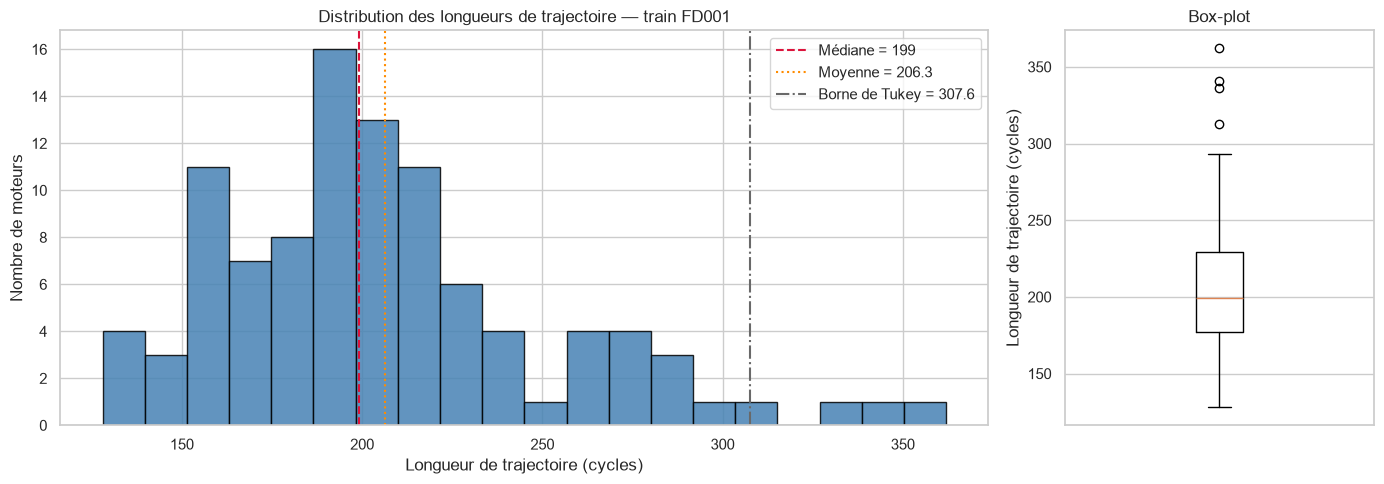

In [10]:
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 1]})

ax_hist.hist(train_lengths, bins=20, color="steelblue", edgecolor="black", alpha=0.85)
ax_hist.axvline(train_lengths.median(), color="crimson", linestyle="--",
                label=f"Médiane = {train_lengths.median():.0f}")
ax_hist.axvline(train_lengths.mean(), color="darkorange", linestyle=":",
                label=f"Moyenne = {train_lengths.mean():.1f}")
ax_hist.axvline(upper_fence, color="dimgray", linestyle="-.",
                label=f"Borne de Tukey = {upper_fence:.1f}")
ax_hist.set(xlabel="Longueur de trajectoire (cycles)", ylabel="Nombre de moteurs",
            title="Distribution des longueurs de trajectoire — train FD001")
ax_hist.legend()

ax_box.boxplot(train_lengths.values)
ax_box.set(ylabel="Longueur de trajectoire (cycles)", title="Box-plot", xticks=[])

fig.tight_layout()
save_figure(fig, "04_longueurs_trajectoires")
plt.show()

**Lecture des résultats.**

| Statistique | Longueur (cycles) |
|---|---|
| Minimum | 128 |
| 5e percentile | 147 |
| 1er quartile | 177 |
| Médiane | 199 |
| Moyenne | 206,31 |
| 3e quartile | 229,25 |
| 95e percentile | 287,3 |
| Maximum | 362 |
| Écart-type | 46,34 |

- La distribution est **asymétrique à droite** : la moyenne (206,3) dépasse la médiane (199), tirée vers le haut par quelques trajectoires longues.
- La moitié centrale des moteurs (intervalle interquartile) vit entre 177 et 229 cycles.
- Quatre moteurs dépassent la borne de Tukey (307,6 cycles) : 67 (313), 96 (336), 92 (341) et 69 (362). Comme tous les contrôles de la section 3 sont satisfaits, ce sont des **trajectoires longues plausibles, pas des erreurs** : elles sont conservées.

**Conséquences méthodologiques.**

- Un apprentissage ligne par ligne donne mécaniquement **plus de poids aux moteurs longs** : le moteur 69 fournit 362 lignes, le plus court 128.
- Les grandes valeurs de RUL (au-delà de 300) ne sont produites que par ces quelques moteurs : elles seront peu représentées (section 9).
- Les performances devront être analysées **par moteur**, et pas seulement en moyenne globale. Une pondération par moteur pourra être testée en modélisation, mais elle n'est pas décidée ici.

> **À retenir —** Q2 : les durées de vie vont de 128 à 362 cycles (rapport ≈ 2,8). Cette hétérogénéité conditionne le split (section 5), la distribution de la cible (section 9) et la manière d'évaluer les modèles.

## 5. Split entraînement / validation par moteur

**Objectif.** Séparer les moteurs **avant** toute analyse susceptible d'orienter des choix de modélisation (features, seuils, scaler, modèle).

- sous-ensemble **analyse / entraînement** : 80 % des moteurs ;
- sous-ensemble **validation** : 20 % des moteurs.

Le split se fait **par `unit_id`** avec `GroupShuffleSplit`, jamais par ligne aléatoire : les cycles d'un même moteur ne peuvent pas se retrouver des deux côtés.

In [11]:
group_split = GroupShuffleSplit(n_splits=1, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE)
analysis_idx, validation_idx = next(group_split.split(train_df, groups=train_df["unit_id"]))

analysis_train = train_df.iloc[analysis_idx].copy()
validation_df = train_df.iloc[validation_idx].copy()

analysis_engines = set(analysis_train["unit_id"].unique())
validation_engines = set(validation_df["unit_id"].unique())

assert analysis_engines.isdisjoint(validation_engines), "Leakage : un moteur apparaît dans les deux ensembles."
assert analysis_engines | validation_engines == set(train_df["unit_id"].unique()), "Des moteurs ont été perdus."
assert len(analysis_train) + len(validation_df) == len(train_df), "Des lignes ont été perdues."

print(f"Moteurs analyse / entraînement : {len(analysis_engines)}")
print(f"Moteurs validation             : {len(validation_engines)}")
print(f"Moteurs communs                : {len(analysis_engines & validation_engines)}")
print(f"Identifiants de validation     : {sorted(int(u) for u in validation_engines)}")

Moteurs analyse / entraînement : 80
Moteurs validation             : 20
Moteurs communs                : 0
Identifiants de validation     : [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


In [12]:
analysis_lengths = trajectory_lengths(analysis_train)
validation_lengths = trajectory_lengths(validation_df)

split_summary = pd.concat(
    {"analysis_train": analysis_lengths.describe(), "validation": validation_lengths.describe()},
    axis=1,
)
split_summary.loc["n_rows"] = [len(analysis_train), len(validation_df)]
split_summary

,analysis_train,validation
count,80.0000,20.0000
mean,207.0125,203.5000
std,47.4564,42.6139
min,128.0000,135.0000
25%,179.7500,165.2500
50%,199.0000,193.5000
75%,216.2500,240.0000
max,362.0000,269.0000
n_rows,16561.0000,4070.0000


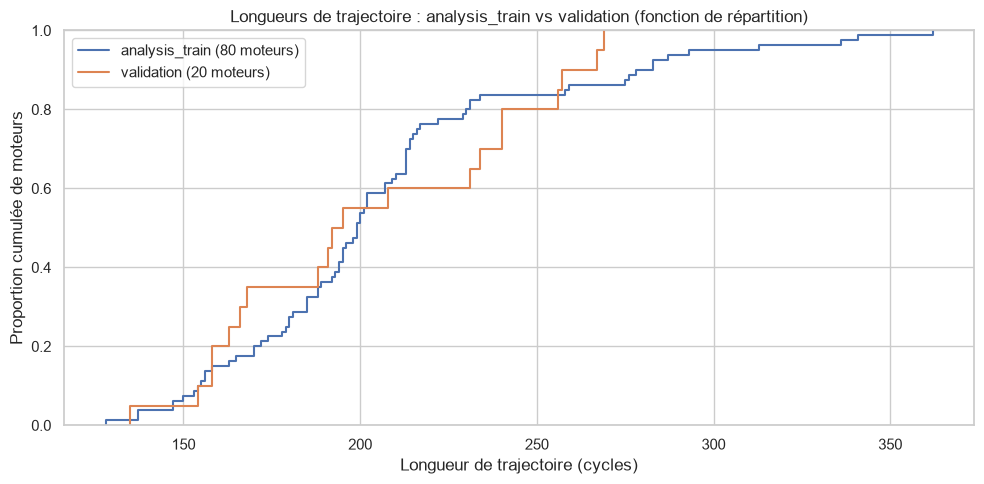

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.ecdfplot(analysis_lengths, ax=ax, label=f"analysis_train ({len(analysis_lengths)} moteurs)")
sns.ecdfplot(validation_lengths, ax=ax, label=f"validation ({len(validation_lengths)} moteurs)")
ax.set(xlabel="Longueur de trajectoire (cycles)", ylabel="Proportion cumulée de moteurs",
       title="Longueurs de trajectoire : analysis_train vs validation (fonction de répartition)")
ax.legend()
fig.tight_layout()
save_figure(fig, "05_split_longueurs")
plt.show()

**Lecture des résultats.**

| | analysis_train | validation |
|---|---|---|
| Moteurs | 80 | 20 |
| Lignes | 16 561 | 4 070 |
| Longueur moyenne | 207,0 | 203,5 |
| Longueur médiane | 199,0 | 193,5 |
| Longueur min – max | 128 – 362 | 135 – 269 |

- Aucun moteur commun ; l'union des deux groupes redonne les 100 moteurs et les 20 631 lignes (vérifié par `assert`).
- Le **centre** des deux distributions est comparable (médianes 199 et 193,5 ; moyennes 207,0 et 203,5).
- **Limite assumée :** la validation ne contient aucun moteur de plus de 269 cycles, alors que les 4 trajectoires les plus longues (plus de 300 cycles) sont toutes dans `analysis_train`. Les très grands RUL (au-delà de 268) ne seront donc **pas évalués** sur cette validation. Avec 20 moteurs seulement, un split unique reste fragile : une **validation croisée par groupes** (`GroupKFold`) est recommandée pour comparer les modèles à l'étape 02.

> **Pourquoi ce split est critique ?** Un split aléatoire ligne par ligne placerait des cycles d'un même moteur des deux côtés : le modèle « reconnaîtrait » des trajectoires déjà vues et les métriques seraient artificiellement optimistes. Le cahier des charges (§6.4 et §22) impose explicitement un split **par moteur**.

> **À retenir —** Q3 : split par moteur 80 / 20, sans recouvrement, figé par la graine et exporté (section 15). **À partir d'ici, toutes les statistiques sont calculées sur `analysis_train` uniquement** ; `validation_df` est réservé à l'évaluation.

## 6. Variabilité des variables

**Objectif.** Distinguer, sur `analysis_train` uniquement, les variables **constantes**, **quasi constantes** et **dynamiques**, sans encore choisir de features définitives.

Comparer les écarts-types bruts serait trompeur : les capteurs ont des unités et des échelles très différentes (de 0,03 à plus de 9 000). La classification repose donc sur deux critères **indépendants de l'échelle** :

- `n_unique` : nombre de valeurs distinctes observées ;
- `dominant_ratio` : part des lignes qui prennent la valeur la plus fréquente (1,0 = variable constante).

Règle : constante si `n_unique = 1` ; quasi constante si `dominant_ratio ≥ NEAR_CONSTANT_THRESHOLD` (95 %) ; dynamique sinon.

In [14]:
analysis_train[FEATURE_COLUMNS].describe(percentiles=[0.01, 0.50, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
setting_1,16561.0,-6.9742e-06,2.1907e-03,-0.0087,-0.0051,0.0000,0.0050,0.0087
setting_2,16561.0,1.9202e-06,2.9264e-04,-0.0006,-0.0005,0.0000,0.0005,0.0006
setting_3,16561.0,1.0000e+02,0.0000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,16561.0,5.1867e+02,0.0000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,16561.0,6.4268e+02,4.9812e-01,641.2100,641.6600,642.6400,643.9200,644.5300
sensor_3,16561.0,1.5905e+03,6.0854e+00,1571.0400,1577.6960,1590.0400,1605.6640,1616.9100
sensor_4,16561.0,1.4089e+03,8.9656e+00,1385.1900,1391.9720,1407.9000,1431.5040,1441.4900
sensor_5,16561.0,1.4620e+01,5.3292e-15,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,16561.0,2.1610e+01,1.3639e-03,21.6000,21.6000,21.6100,21.6100,21.6100
sensor_7,16561.0,5.5337e+02,8.7777e-01,549.8500,551.1800,553.4500,555.0700,556.0600


In [15]:
def dominant_ratio(series):
    """Part de la valeur la plus fréquente (1,0 = variable constante)."""
    return float(series.value_counts(normalize=True, dropna=False).iloc[0])


def variability_category(row):
    if row["n_unique"] == 1:
        return "constante"
    if row["dominant_ratio"] >= NEAR_CONSTANT_THRESHOLD:
        return "quasi constante"
    return "dynamique"


variability = pd.DataFrame({
    "n_unique": analysis_train[FEATURE_COLUMNS].nunique(dropna=False),
    "dominant_ratio": analysis_train[FEATURE_COLUMNS].apply(dominant_ratio),
    "std": analysis_train[FEATURE_COLUMNS].std(),
    "range": analysis_train[FEATURE_COLUMNS].max() - analysis_train[FEATURE_COLUMNS].min(),
})
variability["catégorie"] = variability.apply(variability_category, axis=1)

constant_features = [c for c in FEATURE_COLUMNS if variability.loc[c, "catégorie"] == "constante"]
near_constant_features = [c for c in FEATURE_COLUMNS if variability.loc[c, "catégorie"] == "quasi constante"]
dynamic_features = [c for c in FEATURE_COLUMNS if variability.loc[c, "catégorie"] == "dynamique"]
non_constant_features = [c for c in FEATURE_COLUMNS if c not in constant_features]
dynamic_sensors = [c for c in dynamic_features if c.startswith("sensor_")]

print(f"Constantes      ({len(constant_features)}) : {constant_features}")
print(f"Quasi constantes ({len(near_constant_features)}) : {near_constant_features}")
print(f"Dynamiques      ({len(dynamic_features)}) : {dynamic_features}")

variability.sort_values(["n_unique", "dominant_ratio"], ascending=[True, False])

Constantes      (7) : ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Quasi constantes (1) : ['sensor_6']
Dynamiques      (16) : ['setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


,n_unique,dominant_ratio,std,range,catégorie
setting_3,1,1.0000,0.0000e+00,0.0000,constante
sensor_1,1,1.0000,0.0000e+00,0.0000,constante
sensor_5,1,1.0000,5.3292e-15,0.0000,constante
sensor_10,1,1.0000,2.2205e-16,0.0000,constante
sensor_16,1,1.0000,1.0409e-17,0.0000,constante
sensor_18,1,1.0000,0.0000e+00,0.0000,constante
sensor_19,1,1.0000,0.0000e+00,0.0000,constante
sensor_6,2,0.9810,1.3639e-03,0.0100,quasi constante
sensor_17,13,0.2635,1.5463e+00,12.0000,dynamique
setting_2,13,0.1018,2.9264e-04,0.0012,dynamique


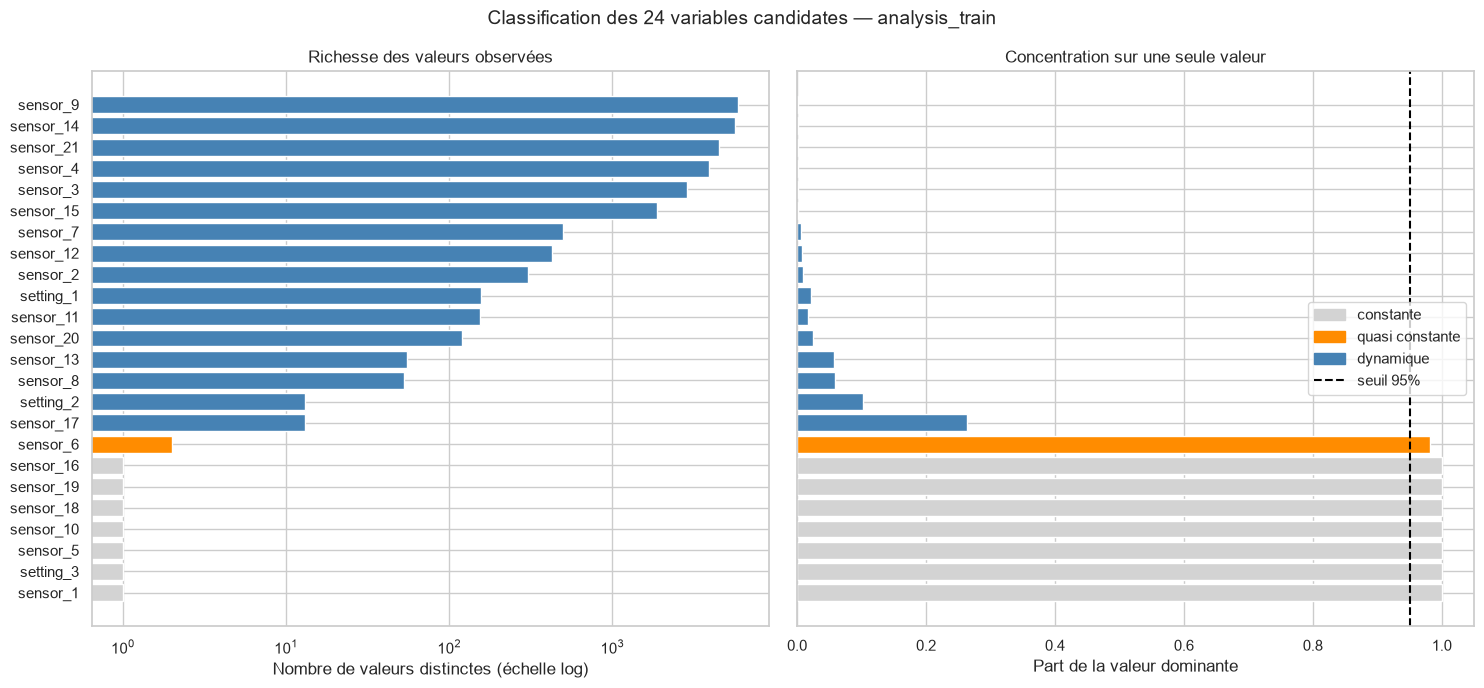

In [16]:
CATEGORY_COLORS = {"constante": "lightgray", "quasi constante": "darkorange", "dynamique": "steelblue"}
plot_df = variability.sort_values("n_unique")
colors = plot_df["catégorie"].map(CATEGORY_COLORS)

fig, (ax_unique, ax_dom) = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

ax_unique.barh(plot_df.index, plot_df["n_unique"], color=colors)
ax_unique.set_xscale("log")
ax_unique.set(xlabel="Nombre de valeurs distinctes (échelle log)", title="Richesse des valeurs observées")

ax_dom.barh(plot_df.index, plot_df["dominant_ratio"], color=colors)
ax_dom.axvline(NEAR_CONSTANT_THRESHOLD, color="black", linestyle="--",
               label=f"Seuil quasi constant = {NEAR_CONSTANT_THRESHOLD:.0%}")
ax_dom.set(xlabel="Part de la valeur dominante", title="Concentration sur une seule valeur")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CATEGORY_COLORS.values()]
ax_dom.legend(handles + [Line2D([0], [0], color="black", linestyle="--")],
              list(CATEGORY_COLORS) + [f"seuil {NEAR_CONSTANT_THRESHOLD:.0%}"], loc="center right")

fig.suptitle("Classification des 24 variables candidates — analysis_train", fontsize=14)
fig.tight_layout()
save_figure(fig, "06_variabilite_variables")
plt.show()

**Lecture des résultats.**

| Catégorie | Variables | Critère observé |
|---|---|---|
| Constantes (7) | `setting_3`, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19` | une seule valeur |
| Quasi constante (1) | `sensor_6` | 2 valeurs : 21,61 (98,1 % des lignes) et 21,60 (1,9 %) |
| Dynamiques (16) | `setting_1`, `setting_2` et 14 capteurs : `sensor_2`, `3`, `4`, `7`, `8`, `9`, `11`, `12`, `13`, `14`, `15`, `17`, `20`, `21` | valeur dominante < 95 % |

Observations complémentaires :

- `sensor_5`, `sensor_10` et `sensor_16` affichent un écart-type de l'ordre de 1e-15 alors que `n_unique = 1` : c'est du **bruit d'arrondi en virgule flottante**, pas une variation réelle. C'est précisément pourquoi la classification repose sur `n_unique` et non sur l'écart-type.
- `setting_1` et `setting_2` varient, mais autour de 0 avec une dispersion minuscule (écarts-types 0,0022 et 0,0003) : c'est cohérent avec **l'unique condition opérationnelle** de FD001. Leur lien avec le RUL est examiné en section 10.
- `sensor_17` est **discret** : 13 valeurs entières, de 388 à 400. `sensor_8` et `sensor_13` n'ont que 53 et 55 valeurs distinctes (résolution de 0,01) : leurs courbes apparaîtront « en escalier ».

**Décisions méthodologiques.**

| Variable(s) | Décision | Statut |
|---|---|---|
| 7 variables constantes | Retrait du pipeline de preprocessing | Acquis — aucune information, et même valeur unique dans le test (section 14) |
| `sensor_6` | Candidat au retrait | À confirmer par ablation en modélisation |
| `setting_1`, `setting_2` | Conservés comme candidats | Intérêt à vérifier (section 10) |
| Variables dynamiques | Candidates | Aucune sélection sur la seule variance |

> **À retenir —** Q4 : 7 variables constantes, 1 quasi constante, 16 dynamiques. Une forte variance n'implique pas une forte valeur prédictive : la variabilité sert à **écarter l'inutile**, pas à désigner les meilleures variables.

## 7. Analyse temporelle des trajectoires

**Objectif.** Observer comment les capteurs évoluent au cours de la vie d'un moteur, d'abord sur des moteurs individuels, puis à l'échelle de la flotte.

### 7.1 Choix de moteurs représentatifs

Une série temporelle ne se juge pas sur un seul moteur choisi à la main. Trois moteurs sont sélectionnés **automatiquement** : ceux dont la longueur est la plus proche des percentiles 10, 50 et 90 de `analysis_train`.

In [17]:
reference_quantiles = {"courte (P10)": 0.10, "médiane (P50)": 0.50, "longue (P90)": 0.90}

representative_engines = {}
for label, q in reference_quantiles.items():
    target_length = analysis_lengths.quantile(q)
    representative_engines[label] = int((analysis_lengths - target_length).abs().idxmin())

pd.DataFrame({
    "unit_id": representative_engines,
    "n_cycles": {label: int(analysis_lengths[uid]) for label, uid in representative_engines.items()},
})

,unit_id,n_cycles
courte (P10),93,155
médiane (P50),26,199
longue (P90),86,278


### 7.2 Trajectoires individuelles des 14 capteurs dynamiques

Pour chaque capteur dynamique : signal brut (trait clair) et moyenne glissante **causale** sur `ROLLING_WINDOW` cycles (trait foncé). « Causale » signifie que chaque point n'utilise que les cycles passés — exactement ce qui sera disponible en production.

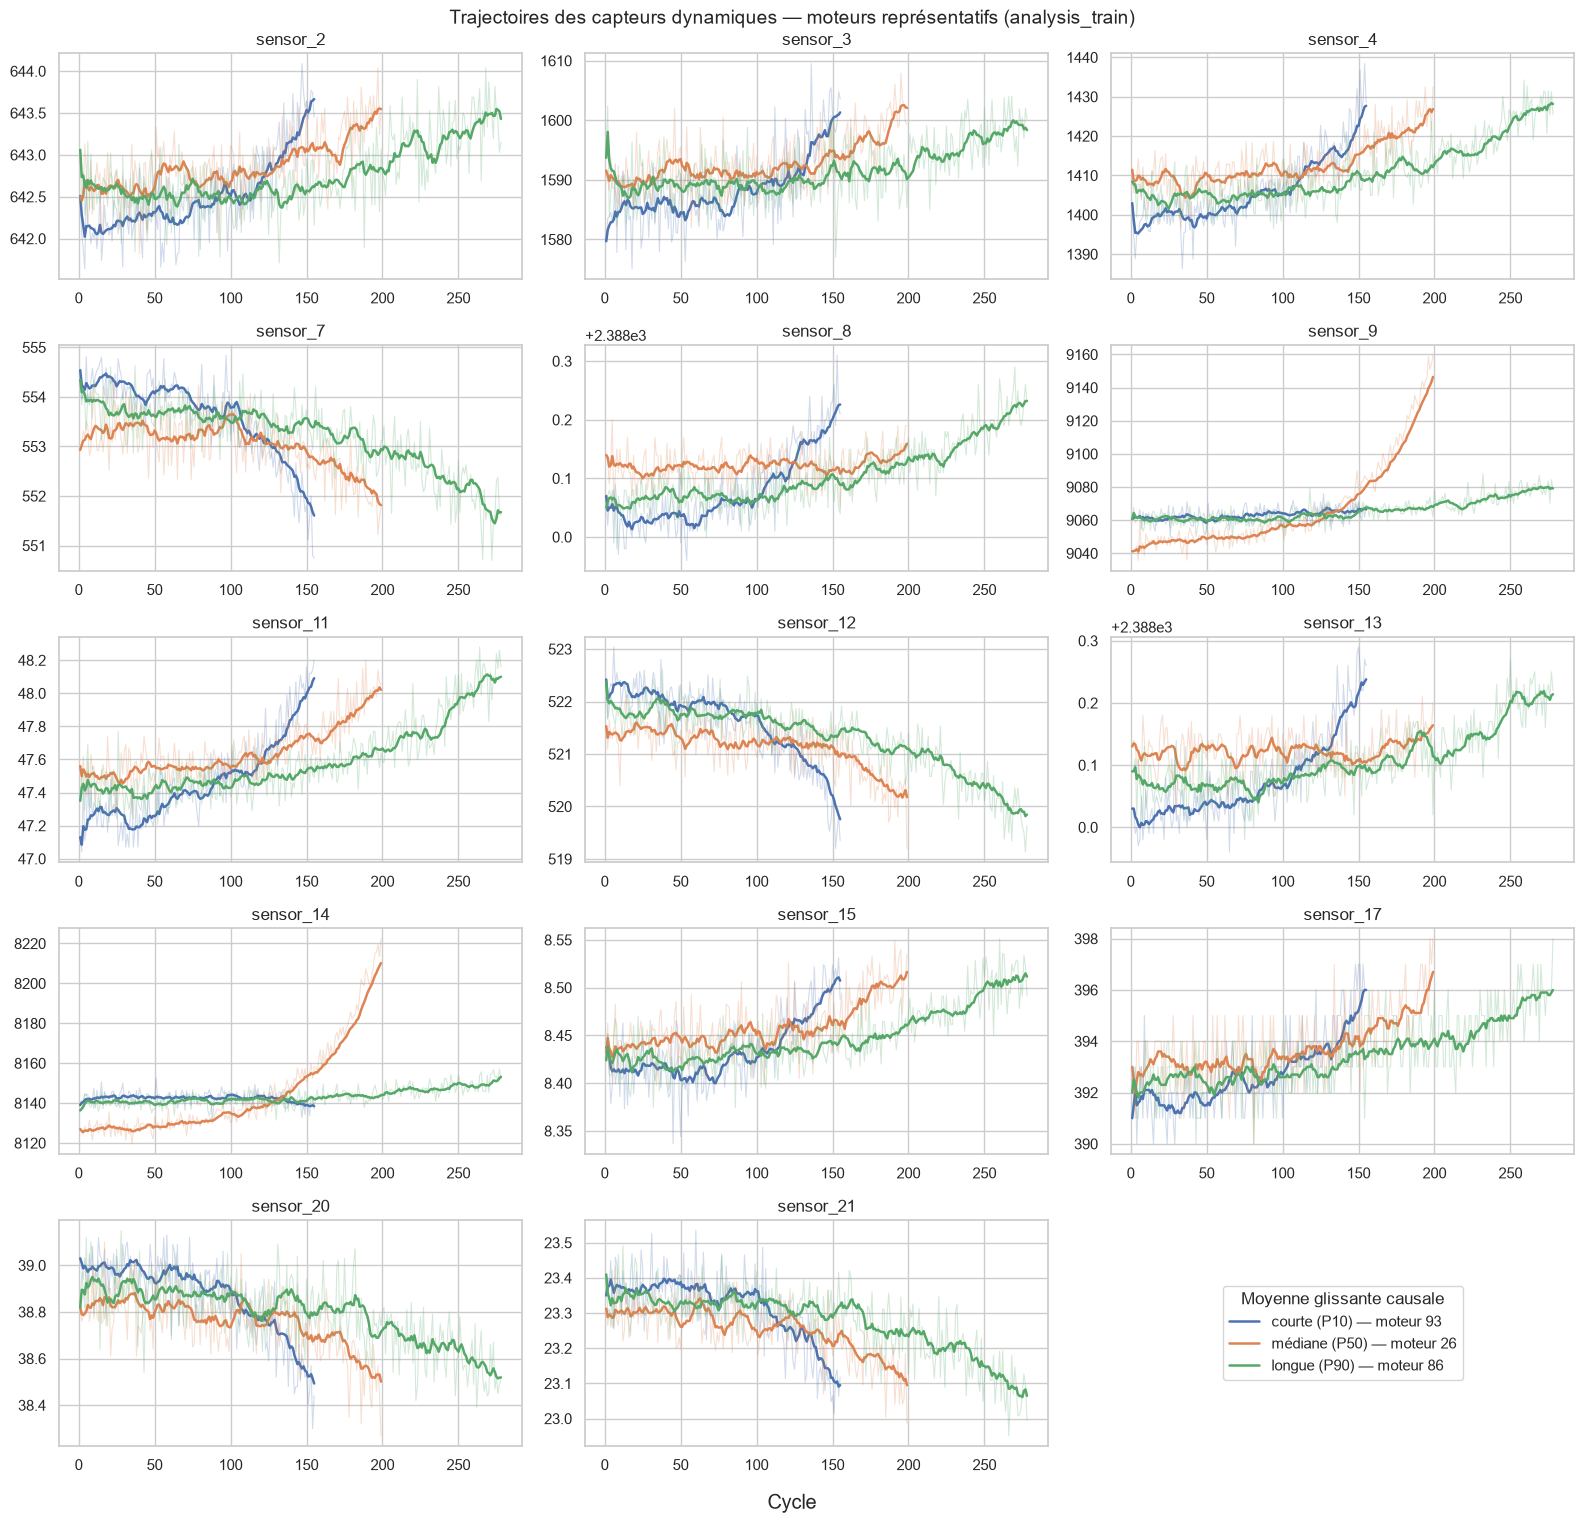

In [18]:
ENGINE_COLORS = dict(zip(representative_engines.values(), sns.color_palette("deep", 3)))

n_cols = 3
n_rows = int(np.ceil(len(dynamic_sensors) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.1 * n_rows))
axes = axes.ravel()

for ax, sensor in zip(axes, dynamic_sensors):
    for label, engine_id in representative_engines.items():
        engine = analysis_train.loc[analysis_train["unit_id"] == engine_id].sort_values("cycle")
        color = ENGINE_COLORS[engine_id]
        ax.plot(engine["cycle"], engine[sensor], color=color, alpha=0.25, linewidth=0.8)
        ax.plot(engine["cycle"], engine[sensor].rolling(ROLLING_WINDOW, min_periods=1).mean(),
                color=color, linewidth=1.8, label=f"{label} — moteur {engine_id}")
    ax.set_title(sensor)

for ax in axes[len(dynamic_sensors):]:
    ax.axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", title="Moyenne glissante causale")

fig.supxlabel("Cycle")
fig.suptitle("Trajectoires des capteurs dynamiques — moteurs représentatifs (analysis_train)", fontsize=14)
fig.tight_layout()
save_figure(fig, "07_trajectoires_moteurs_representatifs")
plt.show()

**Lecture des résultats.**

- Les signaux bruts (traits clairs) sont **très bruités** : d'un cycle à l'autre, la tendance est difficile à lire. La moyenne glissante causale fait apparaître une évolution nette sur la plupart des capteurs.
- Les trois moteurs **ne démarrent pas au même niveau** : par exemple, `sensor_9` et `sensor_14` partent nettement plus bas pour le moteur 26 que pour les moteurs 93 et 86. C'est l'illustration de l'usure initiale inconnue décrite dans la documentation (section 2).
- L'évolution n'est **pas linéaire** : les courbes restent relativement stables pendant une grande partie de la vie, puis s'infléchissent nettement à l'approche de la fin.
- Pour `sensor_4`, `sensor_7`, `sensor_11` et `sensor_12`, les trois moteurs terminent à des niveaux proches malgré des durées de vie très différentes (155, 199 et 278 cycles) : le moteur court atteint simplement cet état **plus vite**. Ce constat ne porte que sur trois moteurs ; il est vérifié à l'échelle de la flotte en 7.3.
- `sensor_9` et `sensor_14` se distinguent : forte hausse en fin de vie pour le moteur 26, évolution faible pour les moteurs 93 et 86 — premier indice du comportement hétérogène étudié en section 11.

### 7.3 Vue flotte en durée de vie normalisée — visualisation EDA uniquement

Les moteurs ayant des durées de vie différentes, chaque trajectoire est ramenée temporairement sur une échelle de 0 à 100 % de sa vie, découpée en `LIFE_BINS` tranches. Pour chaque tranche, on calcule d'abord la moyenne **par moteur**, puis la médiane et l'intervalle interquartile **entre moteurs** : chaque moteur pèse autant, quelle que soit sa longueur.

> ⚠️ **Variable interdite comme feature.** `life_pct` utilise le dernier cycle réel du moteur, inconnu en production avant la panne. Elle sert ici uniquement à la visualisation et est supprimée immédiatement après (voir l'audit de la section 13).

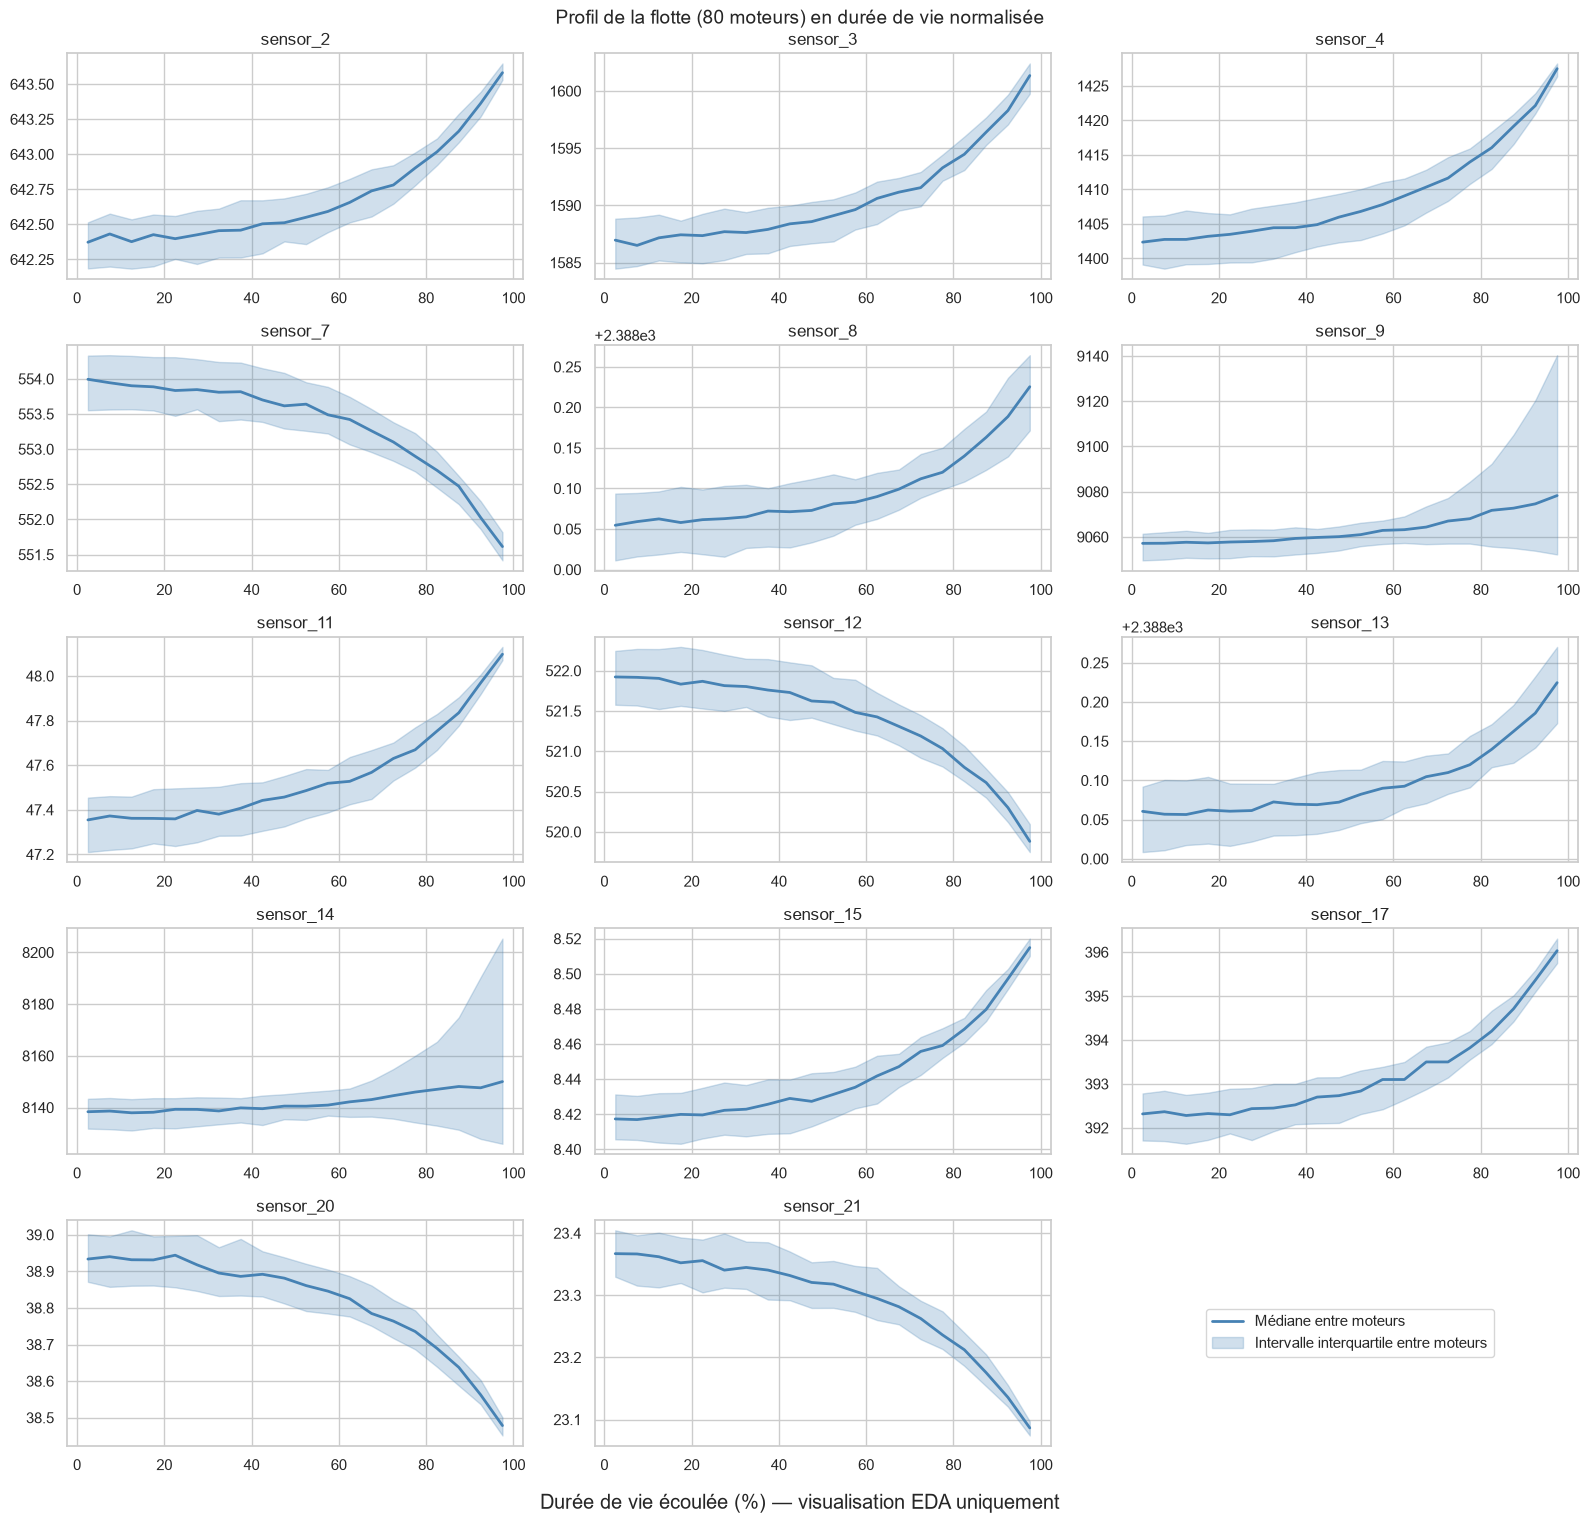

In [19]:
fleet_view = analysis_train[["unit_id", "cycle"] + dynamic_sensors].copy()
fleet_view["life_pct"] = 100 * fleet_view["cycle"] / fleet_view.groupby("unit_id")["cycle"].transform("max")
fleet_view["life_bin"] = np.minimum(fleet_view["life_pct"] // (100 / LIFE_BINS), LIFE_BINS - 1).astype(int)

per_engine_bin = fleet_view.groupby(["unit_id", "life_bin"])[dynamic_sensors].mean()
fleet_q25 = per_engine_bin.groupby("life_bin").quantile(0.25)
fleet_q50 = per_engine_bin.groupby("life_bin").quantile(0.50)
fleet_q75 = per_engine_bin.groupby("life_bin").quantile(0.75)
bin_centers = (fleet_q50.index.to_numpy() + 0.5) * 100 / LIFE_BINS

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.1 * n_rows))
axes = axes.ravel()
for ax, sensor in zip(axes, dynamic_sensors):
    ax.fill_between(bin_centers, fleet_q25[sensor], fleet_q75[sensor], color="steelblue", alpha=0.25)
    ax.plot(bin_centers, fleet_q50[sensor], color="steelblue", linewidth=2)
    ax.set_title(sensor)
for ax in axes[len(dynamic_sensors):]:
    ax.axis("off")
axes[-1].legend(
    [Line2D([0], [0], color="steelblue", linewidth=2), plt.Rectangle((0, 0), 1, 1, color="steelblue", alpha=0.25)],
    ["Médiane entre moteurs", "Intervalle interquartile entre moteurs"],
    loc="center",
)
fig.supxlabel("Durée de vie écoulée (%) — visualisation EDA uniquement")
fig.suptitle(f"Profil de la flotte ({analysis_train['unit_id'].nunique()} moteurs) en durée de vie normalisée", fontsize=14)
fig.tight_layout()
save_figure(fig, "07_profil_flotte_vie_normalisee")
plt.show()

# Nettoyage explicite : aucune variable future ne subsiste dans les données d'analyse.
del fleet_view, per_engine_bin
assert "life_pct" not in analysis_train.columns

**Lecture des résultats.**

- À l'échelle des 80 moteurs, les 14 capteurs dynamiques évoluent de façon **monotone** : 10 augmentent à l'approche de la fin de vie (`sensor_2`, `3`, `4`, `8`, `9`, `11`, `13`, `14`, `15`, `17`) et 4 diminuent (`sensor_7`, `12`, `20`, `21`). Ces sens concordent avec les signes des corrélations de la section 10.
- L'évolution **s'accélère** : stable ou en pente douce pendant la première moitié de la vie, elle devient de plus en plus rapide ensuite ; la majeure partie de la variation intervient dans les 40 derniers pourcents de la vie.
- Pour 10 capteurs (`sensor_2`, `3`, `4`, `7`, `11`, `12`, `15`, `17`, `20`, `21`), la bande interquartile **se resserre** en fin de vie : partis de niveaux différents, les moteurs convergent vers un état final comparable. Elle garde une largeur similaire pour `sensor_8` et `sensor_13`.
- Pour `sensor_9` et `sensor_14`, au contraire, la bande **s'élargit fortement** en fin de vie alors que la médiane bouge peu : les moteurs divergent (section 11.2).

> **À retenir —** Q2 (dynamique) : la dégradation est progressive, **non linéaire** (lente puis accélérée) et partagée par la flotte, avec des niveaux de départ propres à chaque moteur. Deux conséquences pour la modélisation : (1) il faudra capter une **accélération** de tendance, ce qui plaide pour des fenêtres temporelles et des modèles non linéaires ; (2) le début de vie renseigne peu sur la valeur exacte du RUL, ce qui est un argument en faveur du RUL plafonné (section 8.2).

## 8. Construction et validation de la cible RUL

**Objectif.** Construire la cible d'apprentissage et prouver automatiquement qu'elle est correcte.

### 8.1 Définition

Dans le train, chaque trajectoire va jusqu'à la défaillance. Pour un moteur $i$ au cycle $t$, avec $T_i$ son dernier cycle observé :

$$RUL_{i,t} = T_i - t$$

Le RUL est calculé **sans conserver** de colonne `last_cycle` ou `max_cycle` : une telle colonne révélerait la fin future de la trajectoire et pourrait être utilisée par erreur comme feature.

In [20]:
def add_rul(df):
    """Ajoute la cible RUL = dernier cycle du moteur − cycle courant, sans conserver le dernier cycle."""
    out = df.copy()
    out["RUL"] = out.groupby("unit_id")["cycle"].transform("max") - out["cycle"]
    return out


analysis_train = add_rul(analysis_train)
validation_df = add_rul(validation_df)

analysis_train.loc[analysis_train["unit_id"] == representative_engines["médiane (P50)"],
                   ["unit_id", "cycle", "RUL"]].iloc[[0, 1, 2, -3, -2, -1]]

,unit_id,cycle,RUL
5110,26,1,198
5111,26,2,197
5112,26,3,196
5306,26,197,2
5307,26,198,1
5308,26,199,0


In [21]:
def check_rul(df):
    """Contrôles automatiques de cohérence de la cible RUL."""
    ordered = df.sort_values(["unit_id", "cycle"])
    by_engine = ordered.groupby("unit_id")["RUL"]
    return pd.Series({
        "RUL = 0 au dernier cycle": bool((by_engine.min() == 0).all()),
        "RUL = longueur − 1 au premier cycle": bool((by_engine.max() == trajectory_lengths(df) - 1).all()),
        "RUL décroît exactement de 1 par cycle": bool((by_engine.diff().dropna() == -1).all()),
        "RUL entier et positif": bool(pd.api.types.is_integer_dtype(df["RUL"]) and (df["RUL"] >= 0).all()),
        "aucune colonne future conservée": not ({"max_cycle", "last_cycle"} & set(df.columns)),
    })


rul_checks = pd.concat({"analysis_train": check_rul(analysis_train), "validation": check_rul(validation_df)}, axis=1)
assert rul_checks.all().all(), "Incohérence détectée dans la construction du RUL."
rul_checks

,analysis_train,validation
RUL = 0 au dernier cycle,True,True
RUL = longueur − 1 au premier cycle,True,True
RUL décroît exactement de 1 par cycle,True,True
RUL entier et positif,True,True
aucune colonne future conservée,True,True


### 8.2 RUL brut ou RUL plafonné ? — hypothèse à tester, pas une décision

Le RUL brut suppose que l'état du moteur se dégrade linéairement **dès le premier cycle**. Une alternative fréquente dans la littérature C-MAPSS est le RUL **plafonné** (*piecewise linear*) : tant que le moteur est sain, son RUL exact n'est pas observable dans les capteurs, on le limite donc à une valeur maximale. Le cahier des charges (§8.1) impose de traiter ce plafond comme un **hyperparamètre justifié par la validation**. La valeur 125 ci-dessous est purement illustrative.

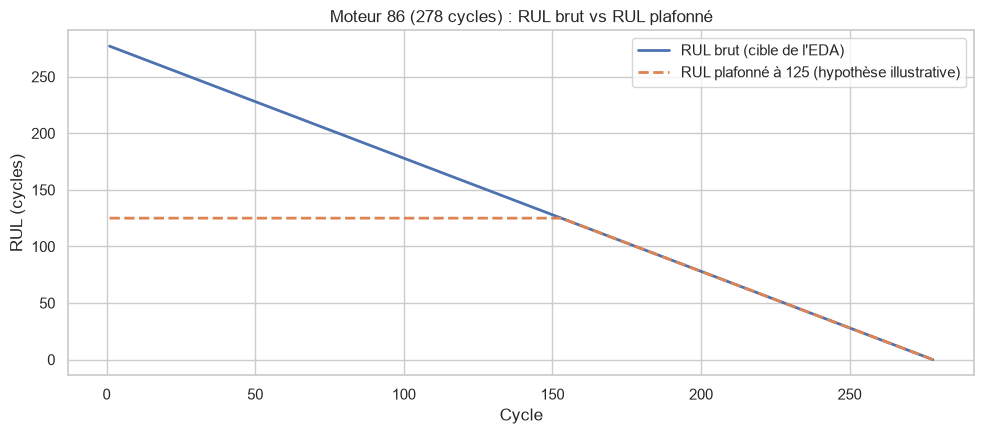

In [22]:
engine_id = representative_engines["longue (P90)"]
engine = analysis_train.loc[analysis_train["unit_id"] == engine_id].sort_values("cycle")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(engine["cycle"], engine["RUL"], linewidth=2, label="RUL brut (cible de l'EDA)")
ax.plot(engine["cycle"], engine["RUL"].clip(upper=ILLUSTRATIVE_RUL_CAP), linestyle="--", linewidth=2,
        label=f"RUL plafonné à {ILLUSTRATIVE_RUL_CAP} (hypothèse illustrative)")
ax.set(xlabel="Cycle", ylabel="RUL (cycles)",
       title=f"Moteur {engine_id} ({len(engine)} cycles) : RUL brut vs RUL plafonné")
ax.legend()
fig.tight_layout()
save_figure(fig, "08_rul_brut_vs_plafonne")
plt.show()

**Lecture des résultats.**

- Les 5 contrôles automatiques sont satisfaits sur `analysis_train` **et** sur `validation_df`. Exemple du moteur 26 (199 cycles) : RUL = 198 au cycle 1, puis 0 au cycle 199.
- Sur la figure, le RUL brut du moteur 86 démarre à 277. Plafonné à 125, il resterait constant jusqu'au cycle 153 puis décroîtrait d'un cycle par cycle.
- La section 7.3 montre que les capteurs varient peu pendant la première moitié de la vie. Demander au modèle de distinguer un RUL de 277 d'un RUL de 200 à partir de capteurs quasi stables est donc probablement mal posé : c'est l'argument du RUL plafonné. Mais c'est un argument **visuel**, que seule la validation pourra confirmer en comparant le RUL brut à plusieurs plafonds (par exemple de 100 à 150).

> **À retenir —** Q5 (construction) : la cible est construite et vérifiée sans fuite d'information. Le **RUL brut** reste la cible de référence de l'EDA ; le plafonnement est une **hypothèse de modélisation** à évaluer dans `02_baseline`, pas une décision prise ici.

## 9. Distribution de la cible RUL

**Objectif.** Comprendre quelles plages de RUL sont bien représentées. Le RUL est une variable **continue** : on ne parle pas de classes déséquilibrées, mais d'une **couverture plus ou moins dense** de la plage de valeurs.

In [23]:
rul_summary = pd.concat(
    {"analysis_train": analysis_train["RUL"].describe(), "validation": validation_df["RUL"].describe()},
    axis=1,
)
rul_summary.loc["part RUL ≤ 125"] = [(analysis_train["RUL"] <= 125).mean(), (validation_df["RUL"] <= 125).mean()]
rul_summary.loc["part RUL > 200"] = [(analysis_train["RUL"] > 200).mean(), (validation_df["RUL"] > 200).mean()]
rul_summary

,analysis_train,validation
count,16561.0000,4070.0000
mean,108.3778,105.4887
std,69.6399,65.6600
min,0.0000,0.0000
25%,51.0000,50.0000
50%,103.0000,101.0000
75%,156.0000,153.0000
max,361.0000,268.0000
part RUL ≤ 125,0.6087,0.6192
part RUL > 200,0.0945,0.0966


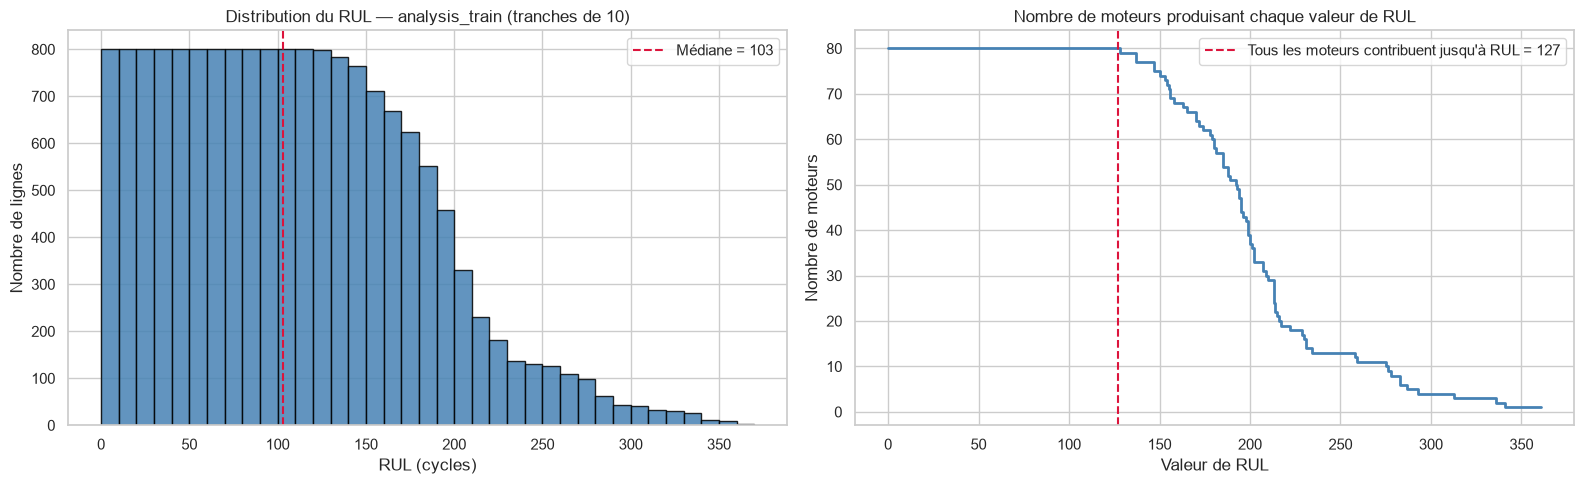

In [24]:
rul_values = np.arange(analysis_train["RUL"].max() + 1)
engines_per_rul = ((analysis_lengths.to_numpy()[:, None] - 1) >= rul_values).sum(axis=0)
full_coverage_limit = analysis_lengths.min() - 1

fig, (ax_hist, ax_cov) = plt.subplots(1, 2, figsize=(16, 5))

ax_hist.hist(analysis_train["RUL"], bins=np.arange(0, analysis_train["RUL"].max() + 11, 10),
             color="steelblue", edgecolor="black", alpha=0.85)
ax_hist.axvline(analysis_train["RUL"].median(), color="crimson", linestyle="--",
                label=f"Médiane = {analysis_train['RUL'].median():.0f}")
ax_hist.set(xlabel="RUL (cycles)", ylabel="Nombre de lignes", title="Distribution du RUL — analysis_train (tranches de 10)")
ax_hist.legend()

ax_cov.step(rul_values, engines_per_rul, where="post", color="steelblue", linewidth=2)
ax_cov.axvline(full_coverage_limit, color="crimson", linestyle="--",
               label=f"Tous les moteurs contribuent jusqu'à RUL = {full_coverage_limit}")
ax_cov.set(xlabel="Valeur de RUL", ylabel="Nombre de moteurs",
           title="Nombre de moteurs produisant chaque valeur de RUL")
ax_cov.legend()

fig.tight_layout()
save_figure(fig, "09_distribution_rul")
plt.show()

**Lecture des résultats.**

| Statistique | analysis_train | validation |
|---|---|---|
| Observations | 16 561 | 4 070 |
| Moyenne | 108,38 | 105,49 |
| Médiane | 103 | 101 |
| Écart-type | 69,64 | 65,66 |
| Maximum | 361 | 268 |
| Part des lignes avec RUL ≤ 125 | 60,87 % | 61,92 % |
| Part des lignes avec RUL > 200 | 9,45 % | 9,66 % |

- **Plateau de 0 à 127 :** le moteur le plus court d'`analysis_train` vit 128 cycles. Les 80 moteurs fournissent donc chacun exactement une ligne pour chaque valeur de RUL de 0 à 127 (graphique de droite).
- **Décroissance au-delà :** une valeur de RUL `r` n'existe que pour les moteurs ayant vécu plus de `r` cycles. Les RUL élevés reposent sur très peu de moteurs : 13 moteurs dépassent 250 cycles, et seulement 4 dépassent 300.
- La forme de la distribution est une **conséquence directe des longueurs de trajectoire**, pas un phénomène physique. Le RUL étant continu, il s'agit d'une **couverture inégale** de la plage de valeurs, pas de classes déséquilibrées.
- Sur leur plage commune, analyse et validation ont des distributions très proches ; la validation s'arrête à 268 (section 5).

**Conséquences.** Les grands RUL seront appris sur peu de moteurs et seront les plus incertains — un argument de plus pour tester un RUL plafonné. Les erreurs devront être analysées **par tranche de RUL** (cahier des charges §17.1 : début de vie, milieu, proche panne), car c'est près de la panne que la précision compte le plus pour la maintenance.

> **À retenir —** Q5 (distribution) : la cible couvre densément la zone de 0 à 127 cycles, la plus utile pour déclencher des alertes, et faiblement les grands RUL.

## 10. Relations variables–RUL : Pearson et Spearman

**Objectif.** Décrire l'association entre chaque variable non constante et le RUL, sur `analysis_train` uniquement.

- **Pearson** mesure une relation **linéaire** ;
- **Spearman** mesure une relation **monotone** (toujours croissante ou toujours décroissante), même non linéaire, et résiste mieux aux valeurs extrêmes.

Comparer les deux renseigne sur la forme de la relation.

> **Précautions.** Les lignes d'un même moteur sont fortement dépendantes (autocorrélation temporelle) : les p-values classiques seraient trompeuses et ne sont donc pas rapportées. Ces coefficients décrivent des associations ; ils ne prouvent ni causalité, ni importance prédictive.

In [25]:
candidate_features = ["cycle"] + non_constant_features

corr_to_rul = pd.DataFrame({
    "pearson": analysis_train[candidate_features].corrwith(analysis_train["RUL"], method="pearson"),
    "spearman": analysis_train[candidate_features].corrwith(analysis_train["RUL"], method="spearman"),
})
corr_to_rul["abs_spearman"] = corr_to_rul["spearman"].abs()
corr_to_rul["spearman_minus_pearson"] = corr_to_rul["spearman"].abs() - corr_to_rul["pearson"].abs()
corr_to_rul = corr_to_rul.sort_values("abs_spearman", ascending=False)
corr_to_rul

,pearson,spearman,abs_spearman,spearman_minus_pearson
cycle,-0.7222,-0.7798,0.7798,0.0576
sensor_11,-0.6839,-0.7078,0.7078,0.0239
sensor_4,-0.6657,-0.6900,0.6900,0.0243
sensor_12,0.6576,0.6805,0.6805,0.0228
sensor_7,0.6445,0.6675,0.6675,0.0230
sensor_15,-0.6313,-0.6561,0.6561,0.0249
sensor_21,0.6241,0.6469,0.6469,0.0228
sensor_20,0.6186,0.6451,0.6451,0.0266
sensor_17,-0.5958,-0.6209,0.6209,0.0251
sensor_2,-0.5970,-0.6201,0.6201,0.0231


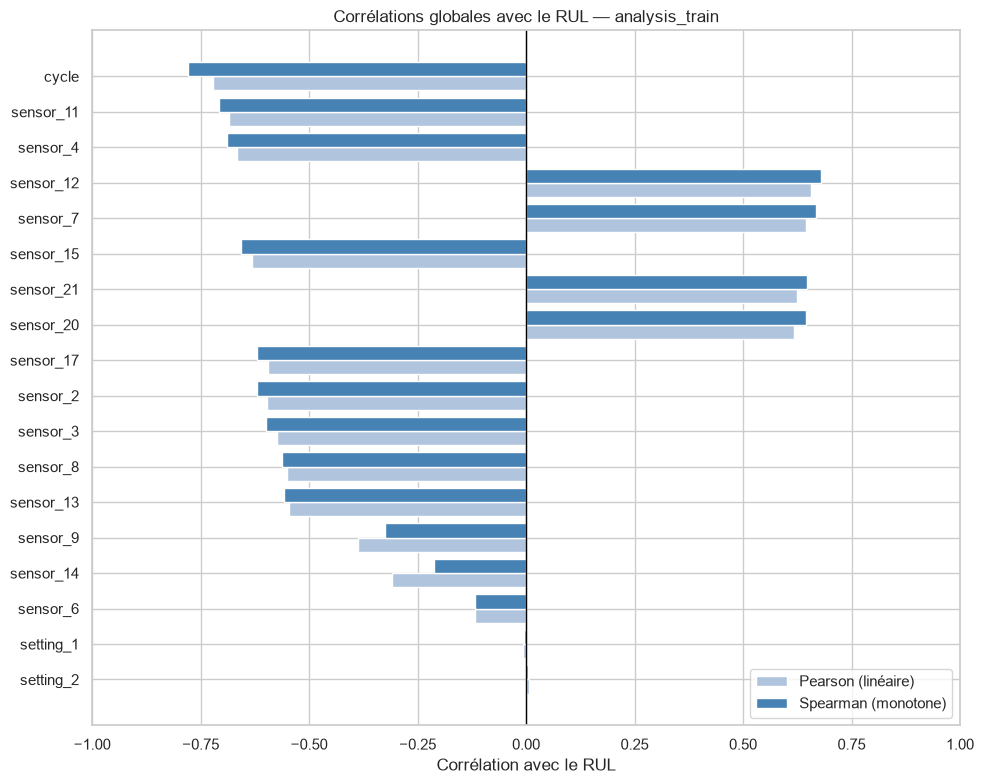

In [26]:
plot_corr = corr_to_rul.sort_values("abs_spearman")
positions = np.arange(len(plot_corr))

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(positions - 0.2, plot_corr["pearson"], height=0.4, color="lightsteelblue", label="Pearson (linéaire)")
ax.barh(positions + 0.2, plot_corr["spearman"], height=0.4, color="steelblue", label="Spearman (monotone)")
ax.set_yticks(positions, plot_corr.index)
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Corrélation avec le RUL", xlim=(-1, 1),
       title="Corrélations globales avec le RUL — analysis_train")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "10_correlations_rul")
plt.show()

**Lecture des résultats.**

| Groupe | Variables | Spearman avec le RUL |
|---|---|---|
| Âge | `cycle` | −0,78 (Pearson −0,72) |
| Tendance nette, négative : le capteur **augmente** à l'approche de la panne | `sensor_11`, `4`, `15`, `17`, `2`, `3`, `8`, `13` | de −0,71 à −0,56 |
| Tendance nette, positive : le capteur **diminue** à l'approche de la panne | `sensor_12`, `7`, `21`, `20` | de +0,68 à +0,65 |
| Tendance faible ou hétérogène | `sensor_9`, `sensor_14` | −0,32 et −0,21 |
| Pas de tendance | `sensor_6`, `setting_1`, `setting_2` | −0,12 ; ≈ 0 ; ≈ 0 |

- **`cycle`** : relation **mécanique**. Au sein d'un moteur, RUL = T_i − cycle, donc la corrélation intra-moteur vaut exactement −1 ; la valeur globale n'est plus faible que parce que T_i varie d'un moteur à l'autre. `cycle` est connu au moment de la prédiction, mais il pousse le modèle vers un raccourci « âge moyen de la flotte » : il faudra le tester **avec et sans** (section 13).
- Pour 12 des 14 capteurs dynamiques, |Spearman| > |Pearson| : les relations sont **monotones mais pas strictement linéaires**, ce qui est cohérent avec une dégradation qui s'accélère en fin de vie (section 7).
- **`sensor_9` et `sensor_14`** sont les seuls capteurs dynamiques pour lesquels |Pearson| > |Spearman| (0,39 contre 0,32 ; 0,31 contre 0,21). Leur relation globale est faible et irrégulière : c'est le signe d'un comportement **non homogène entre moteurs**, étudié en section 11.
- **`setting_1` et `setting_2`** : |r| < 0,01. Dans FD001, ils n'ont aucun lien avec le RUL — cohérent avec une condition opérationnelle unique.

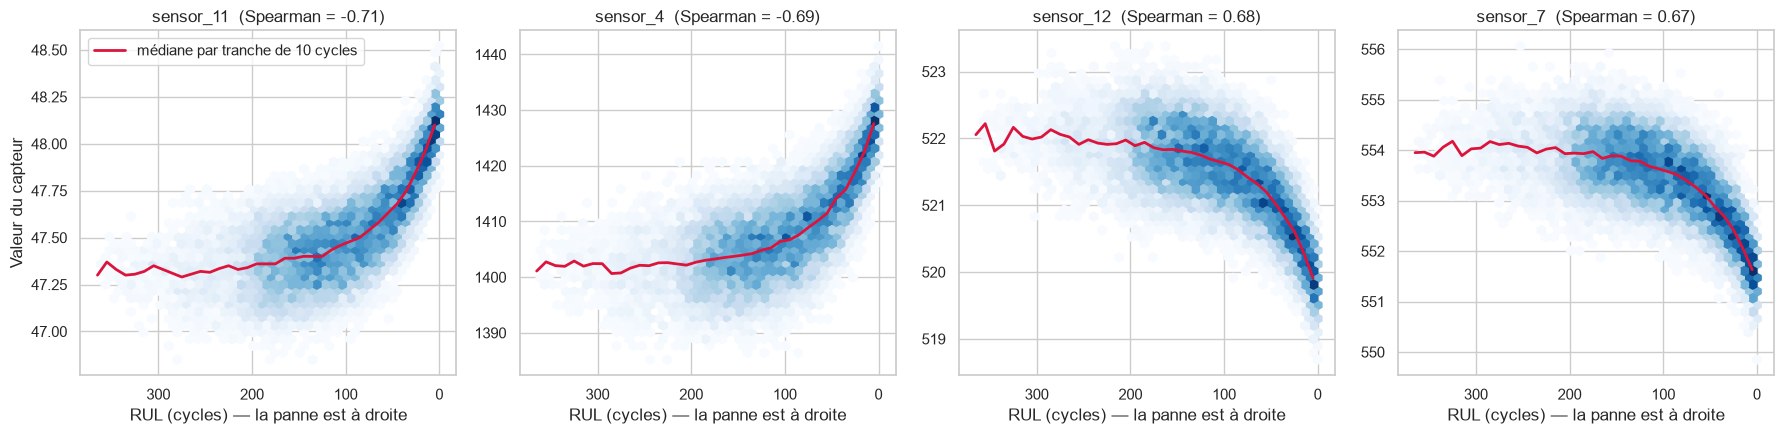

In [27]:
# Forme de la relation pour les 4 capteurs les plus corrélés : densité des points + médiane par tranche de RUL.
top_sensors = corr_to_rul.drop(index="cycle").index[:4]
rul_bin = (analysis_train["RUL"] // 10) * 10 + 5

fig, axes = plt.subplots(1, len(top_sensors), figsize=(18, 4.5))
for ax, sensor in zip(axes, top_sensors):
    ax.hexbin(analysis_train["RUL"], analysis_train[sensor], gridsize=40, cmap="Blues", mincnt=1)
    median_curve = analysis_train.groupby(rul_bin)[sensor].median()
    ax.plot(median_curve.index, median_curve.to_numpy(), color="crimson", linewidth=2,
            label="médiane par tranche de 10 cycles")
    ax.invert_xaxis()
    ax.set(xlabel="RUL (cycles) — la panne est à droite",
           title=f"{sensor}  (Spearman = {corr_to_rul.loc[sensor, 'spearman']:.2f})")
axes[0].set_ylabel("Valeur du capteur")
axes[0].legend(loc="upper left")
fig.tight_layout()
save_figure(fig, "10_relation_top_capteurs_rul")
plt.show()

**Lecture de la figure.** Pour les quatre capteurs les plus corrélés, la médiane (en rouge) est presque **plate pour les RUL élevés**, puis varie de plus en plus vite sur environ les 150 derniers cycles ; la dispersion se resserre près de RUL = 0. Cette forme coudée explique pourquoi Spearman dépasse Pearson : la relation est monotone, mais pas linéaire.

### Comment interpréter ces corrélations

Une corrélation faible ne signifie pas qu'une variable est inutile. Une variable peut être prédictive grâce à :

- une relation non linéaire ;
- une interaction avec d'autres variables ;
- son évolution temporelle (pente, accélération) ;
- une information répartie sur une fenêtre de plusieurs cycles.

À l'inverse, une corrélation calculée en mélangeant les moteurs dépend aussi des différences de niveau entre moteurs (section 11). **Aucune sélection définitive de features n'est donc faite à partir de ces coefficients.**

> **À retenir —** Q6 (global) : 12 capteurs présentent une relation monotone nette avec le RUL (|Spearman| de 0,56 à 0,71), concentrée en fin de vie ; `setting_1`, `setting_2` et `sensor_6` n'en montrent pas ; `sensor_9` et `sensor_14` demandent une analyse moteur par moteur.

## 11. Robustesse des tendances au niveau moteur

**Objectif.** Une corrélation globale peut masquer de fortes différences entre moteurs. Pour chaque capteur non constant, on calcule une corrélation de Spearman avec le RUL **séparément pour chaque moteur**, puis on résume la distribution de ces 80 corrélations.

Question posée : *la tendance observée est-elle récurrente sur l'ensemble de la flotte ?*

Un moteur sur lequel le capteur est constant n'a pas de corrélation définie : il est **exclu explicitement** et compté, plutôt que de produire un avertissement `ConstantInputWarning` et un `NaN` silencieux.

In [28]:
def per_engine_spearman(df, sensor):
    """Spearman(capteur, RUL) moteur par moteur ; ignore les moteurs où le capteur est constant."""
    correlations = {
        unit_id: engine[sensor].corr(engine["RUL"], method="spearman")
        for unit_id, engine in df.groupby("unit_id")
        if engine[sensor].nunique() > 1
    }
    return pd.Series(correlations, name=sensor, dtype=float)


trend_sensors = [s for s in SENSOR_COLUMNS if s not in constant_features]
engine_corr = pd.DataFrame({s: per_engine_spearman(analysis_train, s) for s in trend_sensors})

n_valid = engine_corr.notna().sum()
share_negative = (engine_corr < 0).sum() / n_valid
share_positive = (engine_corr > 0).sum() / n_valid

per_engine_trends = pd.DataFrame({
    "n_engines": n_valid,
    "n_engines_constant": analysis_train["unit_id"].nunique() - n_valid,
    "median_spearman": engine_corr.median(),
    "q25": engine_corr.quantile(0.25),
    "q75": engine_corr.quantile(0.75),
    "same_sign_ratio": np.maximum(share_negative, share_positive),
    "global_spearman": corr_to_rul.loc[trend_sensors, "spearman"],
})
per_engine_trends = per_engine_trends.reindex(per_engine_trends["median_spearman"].abs().sort_values(ascending=False).index)

heterogeneous_sensors = per_engine_trends.index[
    (per_engine_trends["same_sign_ratio"] < SIGN_CONSISTENCY_THRESHOLD)
    & (per_engine_trends["median_spearman"].abs() > 0.5)
].tolist()
print(f"Capteurs à tendance hétérogène entre moteurs : {heterogeneous_sensors}")
per_engine_trends

Capteurs à tendance hétérogène entre moteurs : ['sensor_9', 'sensor_14']


,n_engines,n_engines_constant,median_spearman,q25,q75,same_sign_ratio,global_spearman
sensor_11,80,0,-0.8197,-0.8475,-0.7828,1.0000,-0.7078
sensor_12,80,0,0.8092,0.7474,0.8321,1.0000,0.6805
sensor_4,80,0,-0.7866,-0.8038,-0.7471,1.0000,-0.6900
sensor_7,80,0,0.7762,0.7177,0.8053,1.0000,0.6675
sensor_8,80,0,-0.7688,-0.8202,-0.5824,1.0000,-0.5618
sensor_13,80,0,-0.7620,-0.8165,-0.5912,1.0000,-0.5584
sensor_15,80,0,-0.7223,-0.7450,-0.6731,1.0000,-0.6561
sensor_9,80,0,-0.7161,-0.9132,0.1953,0.7250,-0.3242
sensor_21,80,0,0.7080,0.6617,0.7409,1.0000,0.6469
sensor_20,80,0,0.7075,0.6671,0.7431,1.0000,0.6451


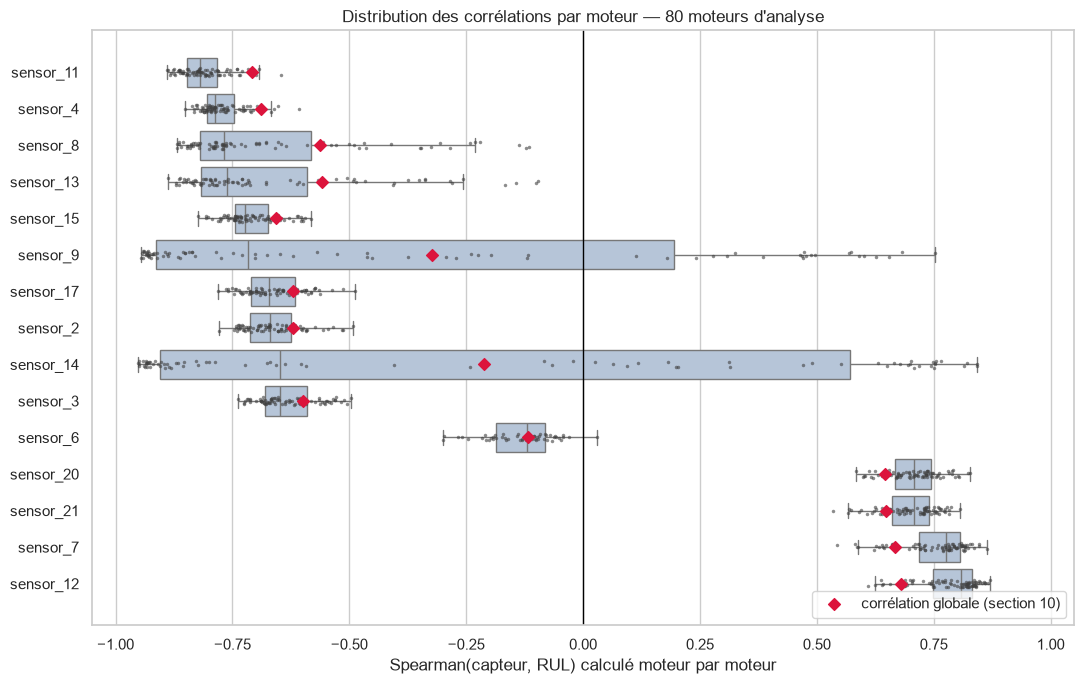

In [29]:
order = per_engine_trends.sort_values("median_spearman").index
long_corr = engine_corr[order].melt(var_name="sensor", value_name="spearman").dropna()

fig, ax = plt.subplots(figsize=(11, 7))
sns.boxplot(data=long_corr, y="sensor", x="spearman", order=order, color="lightsteelblue",
            showfliers=False, ax=ax)
sns.stripplot(data=long_corr, y="sensor", x="spearman", order=order, size=2.5, color="0.25",
              alpha=0.6, ax=ax)
ax.scatter(per_engine_trends.loc[order, "global_spearman"], np.arange(len(order)), marker="D",
           color="crimson", zorder=5, label="corrélation globale (section 10)")
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Spearman(capteur, RUL) calculé moteur par moteur", ylabel="", xlim=(-1.05, 1.05),
       title="Distribution des corrélations par moteur — 80 moteurs d'analyse")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "11_correlations_par_moteur")
plt.show()

**Lecture des résultats.**

- **12 capteurs sur 14** ont le même signe de corrélation sur **100 % des 80 moteurs** : leur tendance est universelle dans la flotte.
- La corrélation **intra-moteur** est systématiquement plus forte que la corrélation globale (losanges rouges) : par exemple `sensor_11` −0,82 en médiane par moteur contre −0,71 en global, `sensor_8` −0,77 contre −0,56. Interprétation : chaque moteur démarre à un niveau différent (usure initiale et variations de fabrication, section 2), ce qui **dilue** la relation quand on mélange les moteurs. Hypothèse à tester en modélisation : des features **relatives au moteur** (écart à son propre début de vie, pente récente) pourraient être plus informatives que les valeurs brutes.
- **`sensor_6`** : la corrélation n'est calculable que sur 51 moteurs (le capteur est constant sur les 29 autres), avec une médiane de −0,12 — cela confirme son faible intérêt.
- **`sensor_9` et `sensor_14`** : médiane élevée (−0,72 et −0,65), mais **signe incohérent** (72,5 % et 60 % de moteurs à corrélation négative) et intervalle interquartile qui traverse 0. Analyse détaillée ci-dessous.

### 11.2 Zoom sur les capteurs à tendance hétérogène

Pour ces capteurs, on compare les moteurs selon le signe de leur corrélation, puis on trace toutes les trajectoires lissées en fonction du RUL.

In [30]:
heterogeneity = pd.DataFrame({
    sensor: {
        "moteurs ρ < 0": int((engine_corr[sensor] < 0).sum()),
        "moteurs ρ > 0": int((engine_corr[sensor] > 0).sum()),
        "longueur moyenne si ρ < 0": analysis_lengths[engine_corr.index[engine_corr[sensor] < 0]].mean(),
        "longueur moyenne si ρ > 0": analysis_lengths[engine_corr.index[engine_corr[sensor] > 0]].mean(),
        "Spearman(ρ du moteur, longueur)": engine_corr[sensor].corr(analysis_lengths, method="spearman"),
    }
    for sensor in heterogeneous_sensors
}).T
heterogeneity

,moteurs ρ < 0,moteurs ρ > 0,longueur moyenne si ρ < 0,longueur moyenne si ρ > 0,"Spearman(ρ du moteur, longueur)"
sensor_9,58.0,22.0,214.0000,188.5909,-0.3114
sensor_14,48.0,32.0,218.0208,190.5000,-0.3095


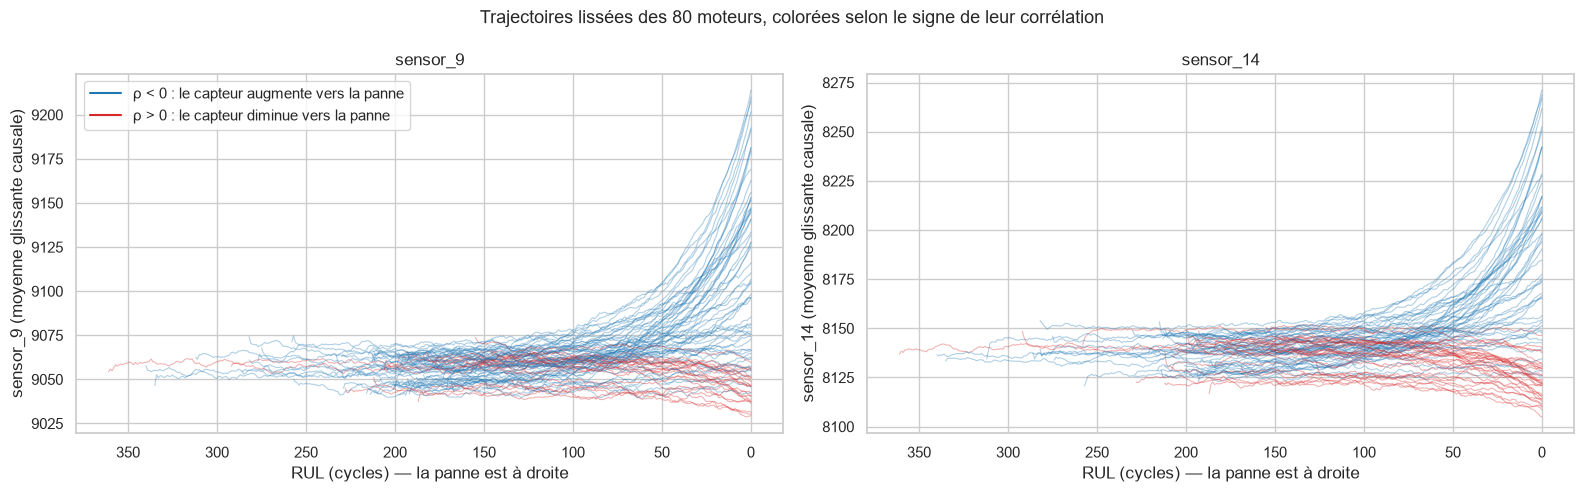

In [31]:
fig, axes = plt.subplots(1, len(heterogeneous_sensors), figsize=(16, 5), squeeze=False)
for ax, sensor in zip(axes.ravel(), heterogeneous_sensors):
    for unit_id, engine in analysis_train.groupby("unit_id"):
        engine = engine.sort_values("cycle")
        color = "tab:red" if engine_corr.loc[unit_id, sensor] > 0 else "tab:blue"
        ax.plot(engine["RUL"], engine[sensor].rolling(ROLLING_WINDOW, min_periods=1).mean(),
                color=color, alpha=0.35, linewidth=0.8)
    ax.invert_xaxis()
    ax.set(xlabel="RUL (cycles) — la panne est à droite", ylabel=f"{sensor} (moyenne glissante causale)",
           title=sensor)
axes[0, 0].legend(
    [Line2D([0], [0], color="tab:blue"), Line2D([0], [0], color="tab:red")],
    ["ρ < 0 : le capteur augmente vers la panne", "ρ > 0 : le capteur diminue vers la panne"],
    loc="upper left",
)
fig.suptitle("Trajectoires lissées des 80 moteurs, colorées selon le signe de leur corrélation", fontsize=13)
fig.tight_layout()
save_figure(fig, "11_capteurs_heterogenes")
plt.show()

**Lecture des résultats.**

| | `sensor_9` | `sensor_14` |
|---|---|---|
| Moteurs ρ < 0 (le capteur augmente vers la panne) | 58 | 48 |
| Moteurs ρ > 0 (le capteur diminue vers la panne) | 22 | 32 |
| Longueur moyenne des moteurs ρ < 0 | 214,0 | 218,0 |
| Longueur moyenne des moteurs ρ > 0 | 188,6 | 190,5 |
| Spearman(ρ du moteur, longueur) | −0,31 | −0,31 |

- En début de vie, les trajectoires des deux familles se superposent dans une même bande. **La divergence apparaît sur les 50 à 100 derniers cycles** : pour une partie des moteurs le capteur monte fortement, pour l'autre il baisse légèrement.
- Le signe est **associé à la durée de vie** : les moteurs dont le capteur baisse vers la panne vivent en moyenne 25 à 28 cycles de moins. Cette association reste modérée (ρ ≈ −0,31) et n'indique rien sur une cause physique.
- La corrélation globale masque ce comportement à deux régimes : un modèle linéaire sur les valeurs brutes moyennerait des évolutions de sens opposés.

**Conséquences pour la modélisation.** Ces capteurs ne sont pas retirés : leur divergence en fin de vie peut être informative pour un modèle non linéaire ou séquentiel. Ils sont marqués `heterogeneous_trend` dans les artefacts et devront faire l'objet d'une **ablation** (avec / sans) pour mesurer leur apport réel.

> **À retenir —** Q6 (robustesse) : 12 tendances sont universelles dans la flotte et plus fortes à l'intérieur de chaque moteur qu'en global ; `sensor_9` et `sensor_14` présentent deux régimes de fin de vie, ce qui interdit de les juger sur leur seule corrélation globale.

## 12. Redondance entre variables

**Objectif.** Repérer les variables qui portent une information très proche. La redondance est étudiée sur **toutes** les variables non constantes, et pas seulement sur celles qui sont corrélées au RUL : deux variables très similaires mais modérément liées à la cible seraient sinon ignorées.

Méthode : matrices de Pearson et de Spearman, liste des paires dépassant `STRONG_CORR_THRESHOLD` (0,80) en valeur absolue, puis regroupement hiérarchique des capteurs. **Aucune variable n'est supprimée ici.**

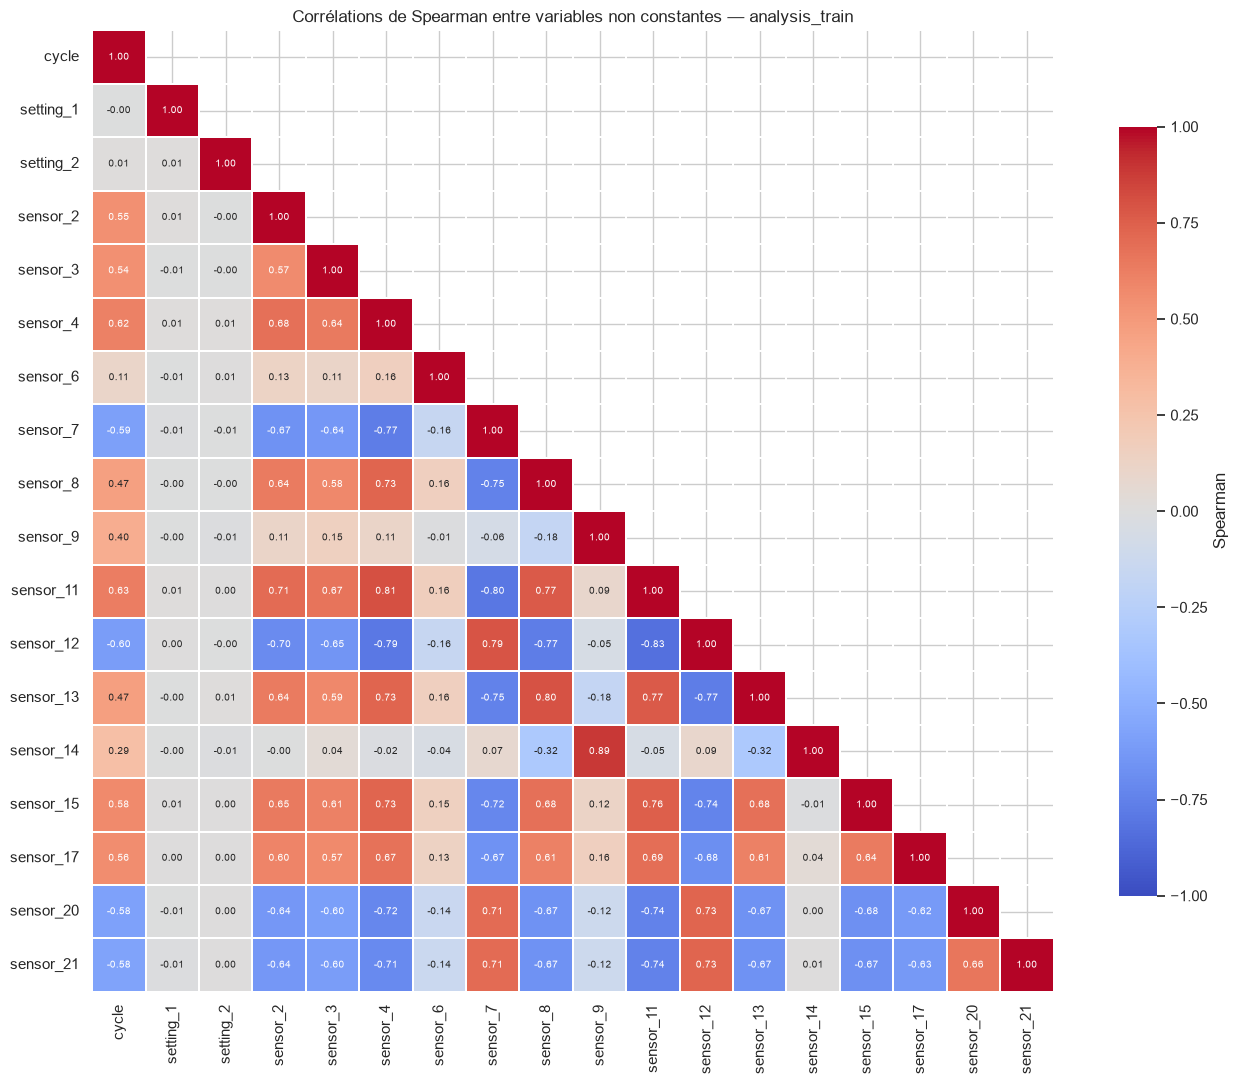

In [32]:
redundancy_features = ["cycle"] + non_constant_features
pearson_matrix = analysis_train[redundancy_features].corr(method="pearson")
spearman_matrix = analysis_train[redundancy_features].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    spearman_matrix,
    mask=np.triu(np.ones_like(spearman_matrix, dtype=bool), k=1),
    cmap="coolwarm", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 7},
    square=True, linewidths=0.3, cbar_kws={"label": "Spearman", "shrink": 0.8}, ax=ax,
)
ax.set_title("Corrélations de Spearman entre variables non constantes — analysis_train")
fig.tight_layout()
save_figure(fig, "12_matrice_correlation")
plt.show()

In [33]:
upper = np.triu(np.ones(pearson_matrix.shape, dtype=bool), k=1)
pairs = pd.DataFrame({
    "pearson": pearson_matrix.where(upper).stack(),
    "spearman": spearman_matrix.where(upper).stack(),
}).dropna().rename_axis(["variable_1", "variable_2"]).reset_index()

strong_pairs = pairs[(pairs[["pearson", "spearman"]].abs() >= STRONG_CORR_THRESHOLD).any(axis=1)]
strong_pairs = strong_pairs.reindex(strong_pairs["pearson"].abs().sort_values(ascending=False).index)
strong_pairs.reset_index(drop=True)

,variable_1,variable_2,pearson,spearman
0,sensor_9,sensor_14,0.9652,0.8879
1,sensor_11,sensor_12,-0.8459,-0.8282
2,sensor_4,sensor_11,0.8276,0.8063
3,sensor_8,sensor_13,0.8260,0.8027
4,sensor_7,sensor_11,-0.8211,-0.8010
5,sensor_7,sensor_12,0.8128,0.7924
6,sensor_4,sensor_12,-0.8121,-0.7929


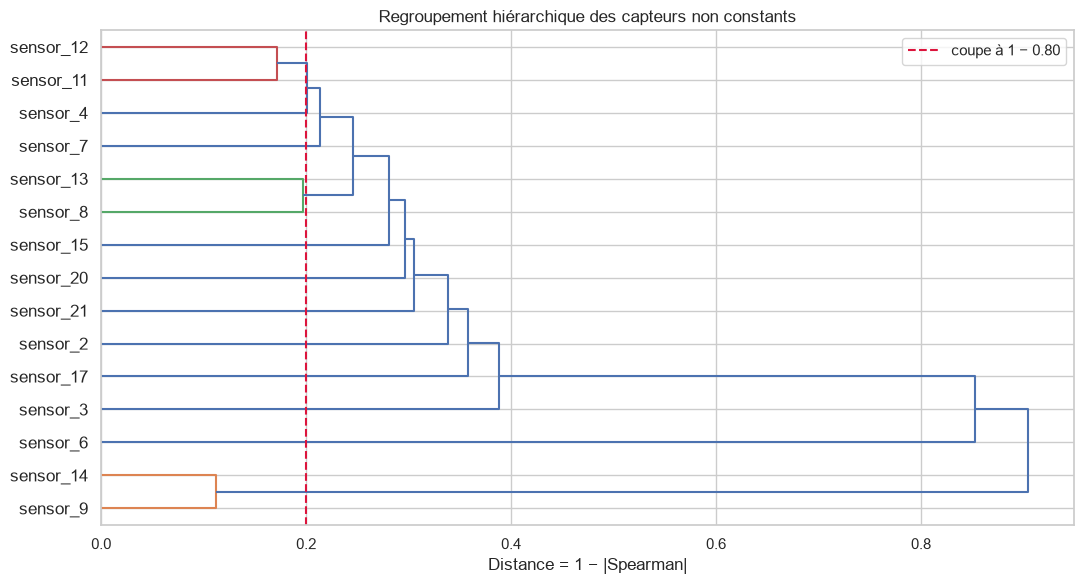

Groupes de capteurs redondants (coupe à |Spearman| moyen ≥ 0,80) :
  - ['sensor_9', 'sensor_14']
  - ['sensor_8', 'sensor_13']
  - ['sensor_11', 'sensor_12']


In [34]:
# Regroupement hiérarchique : distance = 1 − |Spearman|, liaison moyenne.
cluster_sensors = [s for s in SENSOR_COLUMNS if s not in constant_features]
distance = 1 - analysis_train[cluster_sensors].corr(method="spearman").abs()
linkage_matrix = linkage(squareform(distance.to_numpy(), checks=False), method="average")
cut_height = 1 - STRONG_CORR_THRESHOLD

sensor_clusters = pd.Series(fcluster(linkage_matrix, t=cut_height, criterion="distance"), index=cluster_sensors)
redundant_groups = [sorted(group.index, key=lambda s: int(s.split("_")[1]))
                    for _, group in sensor_clusters.groupby(sensor_clusters) if len(group) > 1]

fig, ax = plt.subplots(figsize=(11, 6))
dendrogram(linkage_matrix, labels=cluster_sensors, ax=ax, color_threshold=cut_height, orientation="right")
ax.axvline(cut_height, color="crimson", linestyle="--", label=f"coupe à 1 − {STRONG_CORR_THRESHOLD:.2f}")
ax.set(xlabel="Distance = 1 − |Spearman|", title="Regroupement hiérarchique des capteurs non constants")
ax.legend()
fig.tight_layout()
save_figure(fig, "12_dendrogramme_capteurs")
plt.show()

print("Groupes de capteurs redondants (coupe à |Spearman| moyen ≥ 0,80) :")
for group in redundant_groups:
    print("  -", group)

**Lecture des résultats.**

| Paire | Pearson | Spearman |
|---|---|---|
| `sensor_9` – `sensor_14` | 0,97 | 0,89 |
| `sensor_11` – `sensor_12` | −0,85 | −0,83 |
| `sensor_4` – `sensor_11` | 0,83 | 0,81 |
| `sensor_8` – `sensor_13` | 0,83 | 0,80 |
| `sensor_7` – `sensor_11` | −0,82 | −0,80 |
| `sensor_7` – `sensor_12` | 0,81 | 0,79 |
| `sensor_4` – `sensor_12` | −0,81 | −0,79 |

- Au seuil de 0,80, le regroupement hiérarchique forme **trois groupes** : `sensor_9`/`sensor_14` (la paire la plus redondante, 0,97 en Pearson), `sensor_11`/`sensor_12` et `sensor_8`/`sensor_13`.
- `sensor_4` et `sensor_7` sont liés à `sensor_11` et `sensor_12` par des corrélations voisines de 0,80 et rejoignent ce groupe **juste au-dessus** de la coupe : on peut parler d'un bloc `{4, 7, 11, 12}` fortement corrélé.
- Les autres capteurs dynamiques se rattachent progressivement (distances de 0,24 à 0,39), car ils suivent tous la même tendance de dégradation ; `sensor_6` et le couple `sensor_9`/`sensor_14` restent éloignés du reste.
- **Nuance importante :** une partie de cette redondance vient de la dépendance **commune au RUL**. Deux capteurs qui évoluent tous deux en fin de vie sont corrélés même s'ils mesurent des grandeurs physiques différentes. Une corrélation entre features n'implique ni redondance physique, ni causalité.

**Décision.** Aucune variable n'est supprimée. La gestion de la redondance dépendra du modèle : une régression linéaire non régularisée y est sensible (coefficients instables), une régression Ridge ou un modèle à base d'arbres beaucoup moins. Les groupes exportés permettront de tester en 02 une ablation « un capteur par groupe ».

> **À retenir —** Q7 : 7 paires dépassent |0,80| en valeur absolue ; le cas le plus net est `sensor_9`/`sensor_14` (0,97). La redondance est un **signal à tester**, pas une raison de supprimer.

## 13. Audit anti-data-leakage

**Objectif.** Formaliser, avant la modélisation, ce qui est **autorisé**, **à tester** ou **interdit**. Le data leakage est classé « risque très élevé » dans le cahier des charges (§22) : la parade est un split par moteur et un preprocessing ajusté sur le train uniquement.

In [35]:
leakage_audit = pd.DataFrame(
    [
        ("unit_id", "clé de groupe — pas une feature",
         "sert au split et au fenêtrage ; comme feature, le modèle mémoriserait l'identité de moteurs inconnus en production"),
        ("cycle", "feature candidate — à tester avec et sans",
         "connu au moment de la prédiction, mais lié mécaniquement au RUL (−1 intra-moteur) : risque de raccourci « âge »"),
        ("capteurs dynamiques", "features candidates", "mesurés au cycle courant"),
        ("setting_1, setting_2", "features candidates — faible intérêt attendu", "mesurés au cycle courant ; |r| < 0,01 avec le RUL dans FD001"),
        ("7 variables constantes", "à retirer", "aucune information ; même valeur unique dans le train et le test"),
        ("RUL", "cible uniquement", "quantité à prédire ; ne doit jamais entrer dans X"),
        ("last_cycle / max_cycle", "INTERDIT", "révèle la fin future de la trajectoire"),
        ("life_pct / progress_pct", "INTERDIT comme feature", "nécessite le dernier cycle futur ; visualisation EDA uniquement (§7.3)"),
        ("moyennes glissantes, pentes", "autorisées si causales", "une fenêtre centrée ou future utilise des cycles non encore observés"),
        ("scaler, imputation, sélection", "fit sur le train uniquement", "des statistiques calculées sur validation/test y feraient fuiter de l'information"),
        ("fenêtres temporelles", "par moteur uniquement", "une fenêtre ne doit jamais chevaucher deux trajectoires"),
        ("moteurs de validation", "évaluation uniquement", "jamais utilisés pour ajuster un scaler, des features ou des hyperparamètres"),
        ("RUL_FD001.txt", "RÉSERVÉ AU TEST FINAL", "ne doit influencer ni les features, ni le modèle, ni les hyperparamètres"),
    ],
    columns=["élément", "statut", "raison"],
)

with pd.option_context("display.max_colwidth", None):
    display(leakage_audit)

,élément,statut,raison
0,unit_id,clé de groupe — pas une feature,"sert au split et au fenêtrage ; comme feature, le modèle mémoriserait l'identité de moteurs inconnus en production"
1,cycle,feature candidate — à tester avec et sans,"connu au moment de la prédiction, mais lié mécaniquement au RUL (−1 intra-moteur) : risque de raccourci « âge »"
2,capteurs dynamiques,features candidates,mesurés au cycle courant
3,"setting_1, setting_2",features candidates — faible intérêt attendu,"mesurés au cycle courant ; |r| < 0,01 avec le RUL dans FD001"
4,7 variables constantes,à retirer,aucune information ; même valeur unique dans le train et le test
5,RUL,cible uniquement,quantité à prédire ; ne doit jamais entrer dans X
6,last_cycle / max_cycle,INTERDIT,révèle la fin future de la trajectoire
7,life_pct / progress_pct,INTERDIT comme feature,nécessite le dernier cycle futur ; visualisation EDA uniquement (§7.3)
8,"moyennes glissantes, pentes",autorisées si causales,une fenêtre centrée ou future utilise des cycles non encore observés
9,"scaler, imputation, sélection",fit sur le train uniquement,des statistiques calculées sur validation/test y feraient fuiter de l'information


In [36]:
# Vérifications automatiques de l'état des données en fin d'EDA.
FORBIDDEN_COLUMNS = {"max_cycle", "last_cycle", "life_pct", "progress_pct"}
datasets = {"train_df": train_df, "test_df": test_df, "analysis_train": analysis_train, "validation_df": validation_df}

for name, df in datasets.items():
    leaked = FORBIDDEN_COLUMNS & set(df.columns)
    assert not leaked, f"{name} contient des colonnes interdites : {leaked}"

assert set(analysis_train.columns) == set(COLUMN_NAMES) | {"RUL"}
assert set(validation_df.columns) == set(COLUMN_NAMES) | {"RUL"}
assert "RUL" not in test_df.columns, "Le test ne doit pas porter de RUL dans cette EDA."
assert analysis_engines.isdisjoint(validation_engines)

print("Audit automatique réussi :")
print("  - aucune colonne révélant la fin de trajectoire dans les quatre DataFrames ;")
print("  - analysis_train et validation_df = 26 colonnes d'origine + RUL ;")
print("  - aucun RUL associé au test ;")
print("  - groupes de moteurs disjoints.")

Audit automatique réussi :
  - aucune colonne révélant la fin de trajectoire dans les quatre DataFrames ;
  - analysis_train et validation_df = 26 colonnes d'origine + RUL ;
  - aucun RUL associé au test ;
  - groupes de moteurs disjoints.


> **À retenir —** Q8 : les variables interdites (`last_cycle`, `max_cycle`, `life_pct`) n'existent dans aucun DataFrame, la cible n'est construite que sur le train, et aucune cellule ne lit `RUL_FD001.txt`. Les règles du tableau deviennent le **contrat** du notebook `02_baseline`.

## 14. Contrôle structurel du jeu de test — sans consulter la vérité terrain

**Objectif.** Vérifier que les **entrées** du test sont exploitables et cohérentes avec le train, et identifier les contraintes qu'elles imposent au pipeline. `RUL_FD001.txt` reste fermé : aucune décision n'est prise à partir des labels du test.

In [37]:
same_schema = list(test_df.columns) == list(train_df.columns)
assert same_schema, "Le test n'a pas le même schéma de colonnes que le train."
print(f"Même schéma de colonnes que le train : {same_schema}")

pd.concat({"train": quality_report(train_df), "test": quality_report(test_df)}, axis=1)

Même schéma de colonnes que le train : True


,train,test
n_rows,20631,13096
n_engines,100,100
non_numeric_columns,0,0
missing_values,0,0
infinite_values,0,0
duplicate_rows,0,0
duplicate_unit_cycle,0,0
cycle_gaps,0,0
engines_not_starting_at_cycle_1,0,0


In [38]:
test_lengths = trajectory_lengths(test_df)

length_comparison = pd.concat(
    {"train (jusqu'à la panne)": train_lengths.describe(), "test (tronqué)": test_lengths.describe()},
    axis=1,
)

window_feasibility = pd.DataFrame({
    "W (cycles)": CANDIDATE_WINDOWS,
    "moteurs test avec moins de W cycles": [int((test_lengths < w).sum()) for w in CANDIDATE_WINDOWS],
    "part des moteurs test": [(test_lengths < w).mean() for w in CANDIDATE_WINDOWS],
}).set_index("W (cycles)")

display(length_comparison)
window_feasibility

,train (jusqu'à la panne),test (tronqué)
count,100.0000,100.0000
mean,206.3100,130.9600
std,46.3427,53.5935
min,128.0000,31.0000
25%,177.0000,88.7500
50%,199.0000,133.5000
75%,229.2500,164.2500
max,362.0000,303.0000


,moteurs test avec moins de W cycles,part des moteurs test
W (cycles),,
20,0,0.00
30,0,0.00
50,7,0.07


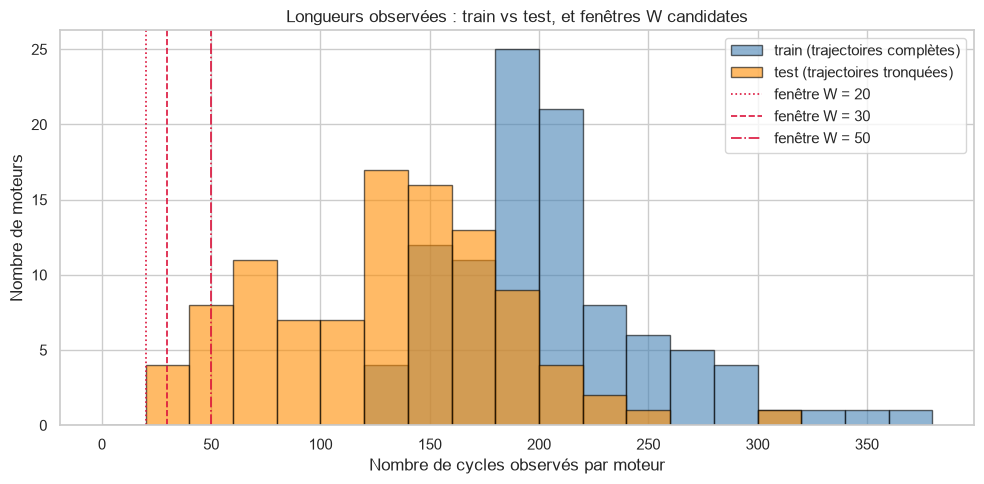

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.arange(0, max(train_lengths.max(), test_lengths.max()) + 20, 20)
ax.hist(train_lengths, bins=bins, alpha=0.6, color="steelblue", edgecolor="black", label="train (trajectoires complètes)")
ax.hist(test_lengths, bins=bins, alpha=0.6, color="darkorange", edgecolor="black", label="test (trajectoires tronquées)")
for w, style in zip(CANDIDATE_WINDOWS, [":", "--", "-."]):
    ax.axvline(w, color="crimson", linestyle=style, linewidth=1.2, label=f"fenêtre W = {w}")
ax.set(xlabel="Nombre de cycles observés par moteur", ylabel="Nombre de moteurs",
       title="Longueurs observées : train vs test, et fenêtres W candidates")
ax.legend(loc="upper right")
fig.tight_layout()
save_figure(fig, "14_longueurs_train_test")
plt.show()

In [40]:
# Les variables constantes du train le sont-elles aussi dans le test, avec la même valeur ?
constant_consistency = pd.DataFrame([
    {
        "variable": feature,
        "valeur train": analysis_train[feature].iloc[0],
        "n_unique test": test_df[feature].nunique(),
        "même valeur unique": test_df[feature].nunique() == 1 and test_df[feature].iloc[0] == analysis_train[feature].iloc[0],
    }
    for feature in constant_features
]).set_index("variable")

assert constant_consistency["même valeur unique"].all()
print("Valeurs de sensor_6 dans le test :", test_df["sensor_6"].value_counts().to_dict())
constant_consistency

Valeurs de sensor_6 dans le test : {21.61: 12704, 21.6: 392}


,valeur train,n_unique test,même valeur unique
variable,,,
setting_3,100.00,1,True
sensor_1,518.67,1,True
sensor_5,14.62,1,True
sensor_10,1.30,1,True
sensor_16,0.03,1,True
sensor_18,2388.00,1,True
sensor_19,100.00,1,True


### 14.2 Cohérence des distributions à stade de vie comparable

Comparer directement toutes les lignes du train et du test serait trompeur : les trajectoires du test sont tronquées, donc observées en moyenne **plus tôt** dans leur vie. On compare donc les `EARLY_LIFE_CYCLES` premiers cycles de chaque moteur, disponibles pour tous les moteurs des deux jeux.

Mesure : **différence moyenne standardisée** (SMD) = (moyenne test − moyenne train) / écart-type train. Repère usuel : |SMD| < 0,1 négligeable, < 0,2 faible.

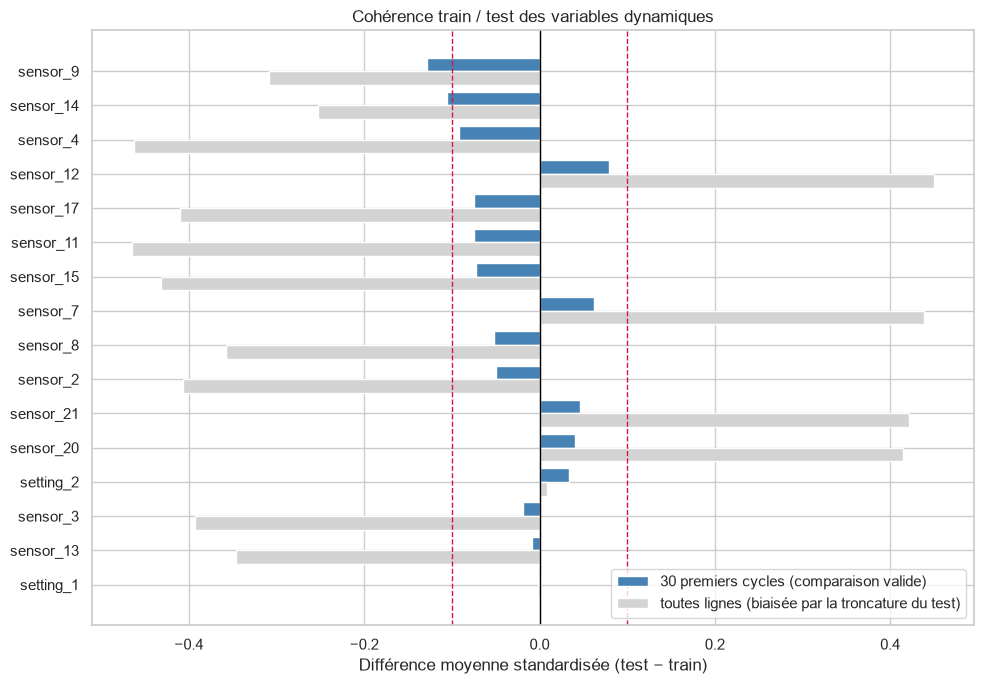

,SMD début de vie,SMD toutes lignes (comparaison naïve)
sensor_9,-0.1290,-0.3086
sensor_14,-0.1052,-0.2532
sensor_4,-0.0920,-0.4622
sensor_12,0.0790,0.4499
sensor_17,-0.0753,-0.4098
sensor_11,-0.0742,-0.4646
sensor_15,-0.0722,-0.4314
sensor_7,0.0626,0.4380
sensor_8,-0.0518,-0.3580
sensor_2,-0.0496,-0.4066


In [41]:
early_train = analysis_train[analysis_train["cycle"] <= EARLY_LIFE_CYCLES]
early_test = test_df[test_df["cycle"] <= EARLY_LIFE_CYCLES]

distribution_shift = pd.DataFrame({
    "SMD début de vie": (early_test[dynamic_features].mean() - early_train[dynamic_features].mean())
                        / early_train[dynamic_features].std(),
    "SMD toutes lignes (comparaison naïve)": (test_df[dynamic_features].mean() - analysis_train[dynamic_features].mean())
                                              / analysis_train[dynamic_features].std(),
})
distribution_shift = distribution_shift.reindex(distribution_shift["SMD début de vie"].abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(10, 7))
positions = np.arange(len(distribution_shift))
ax.barh(positions - 0.2, distribution_shift["SMD début de vie"], height=0.4, color="steelblue",
        label=f"{EARLY_LIFE_CYCLES} premiers cycles (comparaison valide)")
ax.barh(positions + 0.2, distribution_shift["SMD toutes lignes (comparaison naïve)"], height=0.4,
        color="lightgray", label="toutes lignes (biaisée par la troncature du test)")
ax.set_yticks(positions, distribution_shift.index)
for x in (-0.1, 0.1):
    ax.axvline(x, color="crimson", linestyle="--", linewidth=1)
ax.axvline(0, color="black", linewidth=1)
ax.invert_yaxis()
ax.set(xlabel="Différence moyenne standardisée (test − train)", title="Cohérence train / test des variables dynamiques")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "14_coherence_train_test")
plt.show()

distribution_shift

**Lecture des résultats.**

- **Mêmes contrôles, mêmes résultats :** schéma identique, aucune valeur manquante ou infinie, aucun doublon, cycles continus démarrant à 1 pour les 100 moteurs du test.
- **Trajectoires tronquées :** médiane de 133,5 cycles observés, contre 199 dans le train ; minimum 31, maximum 303.
- **Contrainte sur la fenêtre W** (cahier des charges §8.3 : 20, 30 ou 50 cycles) : aucun moteur de test n'a moins de 30 cycles, mais **7 moteurs en ont moins de 50**. Une fenêtre W = 50 imposerait un *padding* ou une stratégie dédiée pour 7 % des moteurs de test ; W = 20 ou W = 30 s'applique partout. Cette contrainte doit être intégrée dès la conception du fenêtrage.
- **Variables constantes :** les 7 variables constantes ont la même valeur unique dans le test, donc leur retrait est sans risque. `sensor_6` y prend les deux mêmes valeurs (21,60 et 21,61).
- **Cohérence des distributions :** sur les 30 premiers cycles, c'est-à-dire à stade de vie égal, toutes les |SMD| sont inférieures à 0,13 et 14 variables sur 16 restent sous 0,1 ; les deux plus élevées sont `sensor_9` (−0,13) et `sensor_14` (−0,11). Train et test proviennent donc du même régime de simulation. La comparaison naïve sur toutes les lignes donne des écarts jusqu'à 0,46 (`sensor_11`) : c'est un **artefact de la troncature** du test (moteurs observés plus tôt dans leur vie), pas une dérive.

> **Règle respectée :** ces comparaisons n'utilisent que les **entrées** du test ; `RUL_FD001.txt` n'est pas lu et aucune décision de modélisation n'en découle.

> **À retenir —** Q9 : le test est sain et cohérent avec le train à stade de vie égal. Il impose une contrainte concrète : seulement **31 cycles d'historique au minimum**, donc W ≤ 30 sans padding.

## 15. Export des artefacts

**Objectif.** Transmettre au notebook `02_baseline` les décisions de l'EDA sous forme de fichiers versionnables plutôt que de valeurs recopiées à la main (cahier des charges §6.4 et §15). Les fichiers sont régénérés à l'identique à chaque exécution.

| Fichier | Contenu |
|---|---|
| `artifacts/eda_fd001/fd001_engine_split.json` | identifiants des moteurs d'analyse et de validation, graine, méthode |
| `artifacts/eda_fd001/fd001_feature_groups.json` | variables constantes, quasi constantes, dynamiques, hétérogènes, groupes redondants |
| `artifacts/eda_fd001/eda_fd001_summary.json` | empreintes des données brutes et chiffres clés de l'EDA |
| `reports/figures/eda_fd001/*.png` | figures du notebook, prêtes pour le rapport |

In [42]:
def to_builtin(value):
    """Convertit récursivement les types NumPy en types Python sérialisables en JSON."""
    if isinstance(value, dict):
        return {str(k): to_builtin(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [to_builtin(v) for v in value]
    if isinstance(value, np.generic):
        return value.item()
    return value


engine_split = {
    "dataset": "FD001",
    "method": "GroupShuffleSplit par unit_id",
    "random_state": RANDOM_STATE,
    "validation_size": VALIDATION_SIZE,
    "analysis_engines": sorted(analysis_engines),
    "validation_engines": sorted(validation_engines),
}

feature_groups = {
    "near_constant_threshold": NEAR_CONSTANT_THRESHOLD,
    "constant": constant_features,
    "near_constant": near_constant_features,
    "dynamic": dynamic_features,
    "heterogeneous_trend": heterogeneous_sensors,
    "redundant_groups": redundant_groups,
    "strong_pairs": strong_pairs[["variable_1", "variable_2", "pearson", "spearman"]].round(4).to_dict("records"),
    "forbidden_as_feature": sorted(FORBIDDEN_COLUMNS | {"unit_id", "RUL"}),
}

eda_summary = {
    "raw_files_sha256": RAW_SHA256,
    "train": {"n_rows": len(train_df), "n_engines": train_df["unit_id"].nunique(),
              "length_min": train_lengths.min(), "length_median": train_lengths.median(), "length_max": train_lengths.max()},
    "test": {"n_rows": len(test_df), "n_engines": test_df["unit_id"].nunique(),
             "length_min": test_lengths.min(), "length_median": test_lengths.median(), "length_max": test_lengths.max(),
             "engines_shorter_than_window": dict(zip(map(str, CANDIDATE_WINDOWS), window_feasibility.iloc[:, 0]))},
    "rul_analysis_train": analysis_train["RUL"].describe().round(4).to_dict(),
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}

if EXPORT_ARTIFACTS:
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    for filename, content in {
        "fd001_engine_split.json": engine_split,
        "fd001_feature_groups.json": feature_groups,
        "eda_fd001_summary.json": eda_summary,
    }.items():
        (ARTIFACT_DIR / filename).write_text(json.dumps(to_builtin(content), indent=2, ensure_ascii=False), encoding="utf-8")

    exported = sorted(p.relative_to(PROJECT_ROOT).as_posix() for p in ARTIFACT_DIR.glob("*.json"))
    figures = sorted(p.name for p in FIGURE_DIR.glob("*.png")) if SAVE_FIGURES else []
    print("Artefacts exportés :", *exported, sep="\n  - ")
    print(f"\n{len(figures)} figures dans {FIGURE_DIR.relative_to(PROJECT_ROOT).as_posix()}/")

Artefacts exportés :
  - artifacts/eda_fd001/eda_fd001_summary.json
  - artifacts/eda_fd001/fd001_engine_split.json
  - artifacts/eda_fd001/fd001_feature_groups.json

15 figures dans reports/figures/eda_fd001/


## 16. Synthèse et décisions

### 16.1 Résultats clés

| Thème | Résultat mesuré | Sections |
|---|---|---|
| Volume | Train : 100 moteurs, 20 631 lignes · Test : 100 moteurs, 13 096 lignes · 26 colonnes | 2 |
| Qualité | 0 manquant, 0 infini, 0 doublon, cycles continus démarrant à 1 — train **et** test | 3, 14 |
| Trajectoires (train) | 128 à 362 cycles, médiane 199, moyenne 206,3 ; 4 moteurs au-delà de 307,6 cycles | 4 |
| Split | 80 moteurs d'analyse / 20 de validation, sans recouvrement ; validation limitée à 269 cycles | 5 |
| Variables | 7 constantes, 1 quasi constante (`sensor_6`), 16 dynamiques dont 14 capteurs | 6 |
| Dynamique | Dégradation monotone, lente puis accélérée, niveaux de départ propres à chaque moteur | 7 |
| Cible | RUL brut validé par 5 contrôles ; couverture complète de 0 à 127 ; 60,87 % des lignes ≤ 125 | 8, 9 |
| Relations | 12 capteurs avec \|Spearman\| de 0,56 à 0,71, signe identique sur 100 % des moteurs | 10, 11 |
| Hétérogénéité | `sensor_9` et `sensor_14` : deux régimes de fin de vie selon les moteurs | 11 |
| Redondance | 7 paires au-delà de \|0,80\| ; `sensor_9`–`sensor_14` = 0,97 (Pearson) | 12 |
| Test | Tronqué (31 à 303 cycles) ; 7 moteurs < 50 cycles ; distributions cohérentes en début de vie | 14 |

### 16.2 Décisions transmises au preprocessing (`02_baseline`)

| # | Décision | Statut | Sections |
|---|---|---|---|
| 1 | Réutiliser le split figé `fd001_engine_split.json` | Acquis | 5, 15 |
| 2 | Retirer les 7 variables constantes | Acquis | 6, 14 |
| 3 | Ajuster scaler, imputation et sélection sur les moteurs d'entraînement uniquement | Acquis | 13 |
| 4 | Construire les fenêtres moteur par moteur, sans traverser deux trajectoires | Acquis | 13 |
| 5 | Choisir W en fonction du test : W ≤ 30 sans padding ; W = 50 exige une stratégie pour 7 moteurs | Contrainte | 14 |
| 6 | Évaluer par moteur et par tranche de RUL, en plus des MAE, RMSE et R² globaux | Acquis | 4, 9 |
| 7 | Comparer RUL brut et RUL plafonné (plusieurs plafonds) | À valider | 7, 8, 9 |
| 8 | Tester `cycle` avec et sans | À valider | 10, 13 |
| 9 | Ablation de `sensor_6`, `setting_1` et `setting_2` | À valider | 6, 10 |
| 10 | Ablation de `sensor_9` et `sensor_14` ; gestion des groupes redondants selon le modèle | À valider | 11, 12 |
| 11 | Tester des features causales relatives au moteur (écart au début de vie, pente récente) | Hypothèse | 7, 11 |
| 12 | Comparer les modèles en validation croisée par groupes (`GroupKFold`) en complément du split figé | Recommandé | 5 |

### 16.3 Ce que cette EDA ne permet pas de conclure

- **L'importance prédictive** d'une variable : seule la performance en validation la mesure.
- **Une causalité** : les corrélations décrivent des associations, calculées sur des lignes non indépendantes.
- **Une interprétation physique** des capteurs : les fichiers ne les nomment pas.
- **La généralisation** à FD002–FD004 (6 conditions opérationnelles, 2 modes de panne) : la stabilité des settings et des tendances observée ici est propre à FD001.

### 16.4 Couverture de l'exigence F-02 du cahier des charges

| Élément exigé par F-02 | Couvert | Sections |
|---|---|---|
| Distributions | ✓ | 4, 6, 9, 14 |
| Valeurs manquantes | ✓ | 3, 14 |
| Variabilité des capteurs | ✓ | 6 |
| Corrélations | ✓ | 10, 11, 12 |
| Trajectoires par moteur | ✓ | 7, 11 |

La cellule suivante revérifie automatiquement chaque chiffre cité dans ce notebook : si les données ou le code changent, elle échoue au lieu de laisser un commentaire devenu faux.

In [43]:
# Contrôle de cohérence texte ↔ résultats : chaque chiffre cité dans les cellules Markdown
# est revérifié ici. Si les données ou le code changent, cette cellule échoue au lieu de laisser
# un commentaire devenu faux.
def close(a, b, tol=0.01):
    return abs(float(a) - float(b)) <= tol

checks = {
    "train : 20 631 lignes, 100 moteurs": train_df.shape == (20631, 26) and train_df["unit_id"].nunique() == 100,
    "test : 13 096 lignes, 100 moteurs": test_df.shape == (13096, 26) and test_df["unit_id"].nunique() == 100,
    "longueurs train 128 / 199 / 362": (train_lengths.min(), train_lengths.median(), train_lengths.max()) == (128, 199, 362),
    "longueur moyenne 206,31 ± 46,34": close(train_lengths.mean(), 206.31) and close(train_lengths.std(), 46.34),
    "P5 = 147 et P95 = 287,3": close(train_lengths.quantile(0.05), 147) and close(train_lengths.quantile(0.95), 287.3),
    "4 moteurs longs : 67, 96, 92, 69": list(long_engines.index) == [67, 96, 92, 69],
    "split 80 / 20 moteurs, 16 561 / 4 070 lignes": (len(analysis_engines), len(validation_engines),
                                                      len(analysis_train), len(validation_df)) == (80, 20, 16561, 4070),
    "validation : longueurs 135 à 269": (validation_lengths.min(), validation_lengths.max()) == (135, 269),
    "7 constantes, sensor_6 quasi constante": constant_features == ["setting_3", "sensor_1", "sensor_5", "sensor_10",
                                                                     "sensor_16", "sensor_18", "sensor_19"]
                                               and near_constant_features == ["sensor_6"],
    "16 dynamiques dont 14 capteurs": len(dynamic_features) == 16 and len(dynamic_sensors) == 14,
    "moteurs représentatifs 93 / 26 / 86": list(representative_engines.values()) == [93, 26, 86],
    "RUL analysis : moyenne 108,38, médiane 103, max 361": close(analysis_train["RUL"].mean(), 108.38)
        and analysis_train["RUL"].median() == 103 and analysis_train["RUL"].max() == 361,
    "RUL validation : moyenne 105,49, max 268": close(validation_df["RUL"].mean(), 105.49) and validation_df["RUL"].max() == 268,
    "couverture complète jusqu'à RUL = 127": full_coverage_limit == 127,
    "parts RUL ≤ 125 : 60,87 % / 61,92 %": close(rul_summary.loc["part RUL ≤ 125", "analysis_train"], 0.6087, 5e-5)
        and close(rul_summary.loc["part RUL ≤ 125", "validation"], 0.6192, 5e-5),
    "parts RUL > 200 : 9,45 % / 9,66 %": close(rul_summary.loc["part RUL > 200", "analysis_train"], 0.0945, 5e-5)
        and close(rul_summary.loc["part RUL > 200", "validation"], 0.0966, 5e-5),
    "analysis_train : 13 moteurs > 250 cycles, 4 > 300": int((analysis_lengths > 250).sum()) == 13
        and int((analysis_lengths > 300).sum()) == 4,
    "groupes redondants {9,14}, {8,13}, {11,12}": sorted(redundant_groups) == [["sensor_11", "sensor_12"],
                                                                              ["sensor_8", "sensor_13"],
                                                                              ["sensor_9", "sensor_14"]],
    "sensor_9 : 58 moteurs ρ < 0 / 22 ρ > 0": (int((engine_corr["sensor_9"] < 0).sum()), int((engine_corr["sensor_9"] > 0).sum())) == (58, 22),
    "sensor_14 : 48 moteurs ρ < 0 / 32 ρ > 0": (int((engine_corr["sensor_14"] < 0).sum()), int((engine_corr["sensor_14"] > 0).sum())) == (48, 32),
    "sensor_11 : Spearman global −0,71, par moteur −0,82": close(corr_to_rul.loc["sensor_11", "spearman"], -0.708, 0.005)
        and close(per_engine_trends.loc["sensor_11", "median_spearman"], -0.820, 0.005),
    "capteurs hétérogènes : sensor_9, sensor_14": sorted(heterogeneous_sensors) == ["sensor_14", "sensor_9"],
    "12 capteurs au signe constant sur 100 % des moteurs": int((per_engine_trends.loc[dynamic_sensors, "same_sign_ratio"] == 1).sum()) == 12,
    "7 paires |corr| ≥ 0,80": len(strong_pairs) == 7,
    "test : longueurs 31 à 303, 7 moteurs < 50 cycles": (test_lengths.min(), test_lengths.max(), int((test_lengths < 50).sum())) == (31, 303, 7),
    "|SMD| début de vie ≤ 0,13, dont 14 sur 16 < 0,1": bool((distribution_shift["SMD début de vie"].abs() < 0.13).all())
        and int((distribution_shift["SMD début de vie"].abs() < 0.1).sum()) == 14,
    "|SMD| naïve maximale ≈ 0,46 (sensor_11)": distribution_shift["SMD toutes lignes (comparaison naïve)"].abs().idxmax() == "sensor_11"
        and close(distribution_shift["SMD toutes lignes (comparaison naïve)"].abs().max(), 0.46, 0.006),
}

consistency = pd.Series(checks, name="vérifié")
assert consistency.all(), f"Chiffres du texte à mettre à jour : {consistency[~consistency].index.tolist()}"
print(f"{len(consistency)} affirmations chiffrées du notebook vérifiées automatiquement.")

27 affirmations chiffrées du notebook vérifiées automatiquement.


## 17. Conclusion scientifique

### Réponses aux questions de l'EDA

| # | Réponse |
|---|---|
| Q1 | Oui : train et test sont structurellement sains (0 manquant, 0 doublon, cycles continus démarrant à 1). Aucune imputation n'est nécessaire. |
| Q2 | 100 trajectoires de 128 à 362 cycles, distribution asymétrique à droite ; la dégradation est monotone, lente puis accélérée, avec des niveaux de départ propres à chaque moteur. |
| Q3 | Par `unit_id`, avant toute analyse orientée cible : 80 / 20 moteurs, sans recouvrement, split figé et exporté. Limite : aucun moteur de validation au-delà de 269 cycles. |
| Q4 | 7 variables constantes (à retirer), 1 quasi constante (`sensor_6`, à tester), 16 dynamiques. |
| Q5 | RUL = T_i − t, construit sans variable future et vérifié automatiquement ; couverture dense de 0 à 127, faible au-delà de 300. |
| Q6 | 12 capteurs suivent une tendance monotone universelle, plus forte à l'intérieur de chaque moteur qu'en global ; `sensor_9` et `sensor_14` présentent deux régimes de fin de vie. |
| Q7 | 7 paires au-delà de 0,80 en valeur absolue, dont `sensor_9`/`sensor_14` (0,97) ; redondance en partie expliquée par la tendance commune de dégradation. |
| Q8 | Variables futures interdites et absentes, preprocessing ajusté sur le train seulement, fenêtres par moteur, vérité terrain du test fermée. |
| Q9 | Test cohérent avec le train à stade de vie égal ; il impose au moins 31 cycles d'historique, donc W ≤ 30 sans padding. |

### Limites

- Données **simulées** (C-MAPSS) : les conclusions décrivent le simulateur, pas un parc de moteurs réels.
- Un seul sous-ensemble, FD001 : une condition opérationnelle et un mode de panne.
- Une validation de 20 moteurs seulement, sans trajectoire très longue.
- Des analyses univariées et bivariées : les interactions entre capteurs ne sont pas explorées ici ; elles relèvent des modèles.

### Conclusion

Cette EDA ne désigne pas prématurément les « meilleurs capteurs ». Elle établit ce que les données permettent réellement d'observer — intégrité des séries, hétérogénéité des trajectoires, dégradation non linéaire, tendances robustes ou hétérogènes, redondances — et en tire des décisions **chiffrées, vérifiées automatiquement et exportées**.

Les corrélations et les graphiques servent à **formuler des hypothèses** ; leur valeur prédictive sera mesurée par des modèles comparés sur des moteurs de validation jamais utilisés pour l'entraînement. Cette séparation entre **observation, hypothèse et validation** rend la démarche scientifiquement défendable et prépare directement le baseline RUL du projet SentinelX AI.